# Cell cycle dependencies



In [2]:
import sys
import scipy.stats as stats
import re
import matplotlib.colors as mcolors

import builtins
builtins.NAMING = "new"

sys.path.insert(0, "../../")
from RealTrace_paper_analysis.plotting_src.header_settings import *

from RealTrace_paper_analysis.plotting_src.read_ggp_run import * # you might need to change these two line, such that you can use read ggp_run
from RealTrace_paper_analysis.plotting_src.cells_utils import * # you might need to change these two line, such that you can use read ggp_run
from RealTrace_paper_analysis.plotting_src.read_utils import * # you might need to change these two line, such that you can use read ggp_run


from RealTrace_paper_analysis.plotting_src.cell_cycle_corr import *


%config InlineBackend.figure_format ='retina'
%reload_ext autoreload
%autoreload 2



header_setting.py: using new naming
header_setting.py: using new naming


In [3]:

def compose_title_from_filename(filename):
    title = "Condition: " + filename.split("/")[-1].split("_")[0] + ", Promorter: " + filename.split("/")[-1].split("_")[1]
    return title 
    
def get_suffix_files(directory, suffix='prediction.csv'):
    # given a directory returns all files that end with suffix
    entries = os.listdir(directory)
    final_files = []
    for e in entries:
        if e.endswith(suffix):
            final_files.append( os.path.join(directory, e) )
    return final_files

def get_plotfile_base(files, subdir=None):
    # given a list of files returns base for plot output: example_{:s}.pdf
    final_files = []
    for file in files:
        if subdir != None:
            split = file.split('/')[:-1]
            new_dir = os.path.join(*split, subdir)
            if not os.path.exists(new_dir):
                os.mkdir(new_dir) 
            plot_file = os.path.join(new_dir, file.split('/')[-1])[:-4]+'_{:s}.pdf'
        else:   
            plot_file = file[:-4]+'_{:s}.pdf'
            
        final_files.append(plot_file)
    return final_files




prediction_files = sort_by_condition(get_suffix_files("../../data_realtrace_paper/ecoli_data/", suffix='prediction.csv')) # get all prediction file in directory
# plot_dir = mk_missing_dir(os.path.join( *prediction_files[0].split('/')[:-1], "plots" ))
len(prediction_files)

12

## added_xaxis_parametrization_dependence

In [4]:
def added_volume_dependence(filenames,  
                            xlim=[None, None], 
                            ylim=[None, None],
                            hist_xlim=[None, None],
                            outfile=None, 
                            show=True, 
                            norm_q=False, 
                            norm_l=False,
                            plot_scatter=False,
                            plot_all=False,
                            xaxis_parameter="volume",
                            alignment="norm", 
                            growth_rate_unit=60,
                            label="both",
                            title=None,
                            interpolate=None,
                            color_code="condition", 
                            bins=10, 
                            show_cc_corr=False,
                           legend=True):
    
    """ needs a prediction file, start, stop, step refers to cells """

    # fig, ax = plt.subplots(1, 3, figsize=(16, 3))
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))

    ax0b, ax0, ax1 = ax[0], ax[1], ax[2]

    for a in [ax0, ax1, ax0b]:
        a.set_title(title)
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)
        a.spines['right'].set_color('none')
        a.yaxis.tick_left()
        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()

    longest_cc = []
    for filename in filenames:
            
        data_set_name = re.split('_f\d', filename.split('/')[-1] )[0]
        condition = data_set_name.split("_")[0]
        promoter = data_set_name.split("_")[1]
        
        if label=="both":
            legend_title = None
            labeli = condition + " " +promoter
        elif label=="condition":
            legend_title = promoter
            labeli = condition
        elif label=="promoter":
            legend_title = condition
            labeli = promoter
                
        altcolor_by_promoter = {p: col for p,col  in zip(['hi1','hi3','rplN','rrnB'], ["#2ca02c" ,"#98df8a" ,"#d62728" ,"#ff9896"])}
        altcolor_by_condition = {cond: col for cond,col  in zip(conditions, ["#101518", "#5e798f", "#95a9ba", "#adbdc9" ])}

        condition_color = altcolor_by_condition[condition]
        promoter_color = altcolor_by_promoter[promoter]
            
        data = pd.read_csv(filename, skiprows=header_lines(filename))
        cells_data = df2ggp_cells(data)

        collect_mean_l = np.array([])
        collect_var_l = np.array([])

        collect_mean_q = np.array([])
        collect_var_q = np.array([])

        xaxis = np.array([])
        xaxis_cc = np.array([])
        if interpolate!=None:
            if interpolate=="auto":
                n_d = 0
                for cell in cells_data:
                    n_d += len(cell.time)
                n_interpolate=int(n_d/len(cells_data))
                bins=n_interpolate
            else:
                n_interpolate = interpolate
                bins=n_interpolate
        
        for i, cell in enumerate(cells_data):
            if len(cell.time)<2:
                continue
                
            if xaxis_parameter == "volume":
                single_cell_xaxis = np.exp(cell.mean_x)
            elif xaxis_parameter == "time":
                single_cell_xaxis = np.array(cell.time)
            
            if alignment=="norm":                    
                dx = (single_cell_xaxis -single_cell_xaxis[0])  \
                    / (single_cell_xaxis[-1] - single_cell_xaxis[0]) 
                
            elif alignment== "birth":
                dx = single_cell_xaxis - single_cell_xaxis[0]
            else:
                return
            
            if interpolate!=None:
                linspace = np.linspace(dx[0], dx[-1], n_interpolate)
                cell.mean_l=np.interp(linspace, dx, cell.mean_l)
                cell.cov_ll=np.interp(linspace, dx, cell.cov_ll)
                
                cell.mean_q=np.interp(linspace, dx, cell.mean_q)
                cell.cov_qq=np.interp(linspace, dx, cell.cov_qq)
                dx = linspace
            

            xaxis_cc = np.append(xaxis_cc, single_cell_xaxis[-1] - single_cell_xaxis[0])
            xaxis = np.append(xaxis, dx)
                
            collect_mean_l = np.append(collect_mean_l, cell.mean_l)
            collect_var_l = np.append(collect_var_l, cell.cov_ll)

            collect_mean_q = np.append(collect_mean_q, cell.mean_q)
            collect_var_q = np.append(collect_var_q, cell.cov_qq)
            
        mean_l, bin_edges,_ = stats.binned_statistic(xaxis, collect_mean_l,statistic='mean', bins=bins)
        sum_l, _,_   = stats.binned_statistic(xaxis, collect_var_l, statistic='sum', bins=bins)
        count_l, _,_   = stats.binned_statistic(xaxis, collect_var_l, statistic='count', bins=bins)

        std_l = np.sqrt(sum_l / count_l**2)
        
        if norm_l:
            ax0.axhline(1, color="grey", ls='--')
            normalization_l = np.mean(collect_mean_l)
            mean_l = mean_l/normalization_l
            std_l = std_l/normalization_l
            collect_mean_l/=normalization_l
        
        ## q
        mean_q, bin_edges,_ = stats.binned_statistic(xaxis, collect_mean_q,statistic='mean', bins=bins)
        sum_q, _,_   = stats.binned_statistic(xaxis, collect_var_q, statistic='sum', bins=bins)
        count_q, _,_   = stats.binned_statistic(xaxis, collect_var_q, statistic='count', bins=bins)

        std_q = np.sqrt(sum_q / count_q**2)
        if norm_q:
            ax1.axhline(1, color="grey", ls='--')
            normalization_q = np.mean(collect_mean_q)
            mean_q = mean_q/normalization_q
            std_q = std_q/normalization_q
            collect_mean_q = collect_mean_q/normalization_q
            
        ax0.plot(bin_edges[:-1]+np.diff(bin_edges)/2, mean_l, color=condition_color)
        ax0.fill_between(bin_edges[:-1]+np.diff(bin_edges)/2,
                         mean_l+std_l, 
                         mean_l-std_l, 
                         alpha=0.6, color=condition_color)


        ax1.plot(bin_edges[:-1]+np.diff(bin_edges)/2, 
                 mean_q, 
                 color=promoter_color, label=labeli)
        ax1.fill_between(bin_edges[:-1]+np.diff(bin_edges)/2, mean_q+std_q, mean_q-std_q, alpha=0.5, 
                         color=promoter_color)
        
        if plot_all:
            for i, cell in enumerate(cells_data):
                if len(cell.time)<2:
                    continue

                if xaxis_parameter == "volume":
                    single_cell_xaxis = np.exp(cell.mean_x)
                elif xaxis_parameter == "time":
                    single_cell_xaxis = np.array(cell.time)

                if alignment=="norm":                    
                    dx = (single_cell_xaxis -single_cell_xaxis[0])  \
                        / (single_cell_xaxis[-1] - single_cell_xaxis[0]) 

                elif alignment== "birth":
                    dx = single_cell_xaxis - single_cell_xaxis[0]
                else:
                    return

                if interpolate!=None:
                    linspace = np.linspace(dx[0], dx[-1], n_interpolate)
                    dx = linspace
                ax0.plot(dx, cell.mean_l/normalization_l, color="tab:grey", zorder=-10, alpha=0.05)
                ax1.plot(dx, cell.mean_q/normalization_q, color="tab:grey", zorder=-10, alpha=0.05)
                
        ax0b.plot(np.append(np.sort(xaxis_cc), 1e4),np.append(np.linspace(0.0,1.0,len(xaxis_cc)), 1), color=condition_color)
        longest_cc.append(np.max(xaxis_cc))
        

    ax0b.set_xlim([0, 5])
    ax0.set_ylabel(r"growth $\lambda/\bar{\lambda}$")   
    ax1.set_ylabel(r"prod. $q/\bar{q}$")   
    
    for a in [ax0, ax1]:
        a.set_xticks(np.arange(0, 1.25, 0.25))
        a.set_xticklabels(["0", "1/4", "1/2", "3/4", "1"])

    for a in ax:
        ax1.legend(loc='upper center', bbox_to_anchor=(0.5, 1), ncol=2,  title_fontsize=MEDIUM_SIZE)
        # ax1.legend(loc='center left', bbox_to_anchor=(0.98, 0.5), ncol=1,  title_fontsize=MEDIUM_SIZE)

                
    ax0b.set_xlabel("added cell length")  
    ax0.set_xlabel("norm. added cell length")  
    ax1.set_xlabel("norm. added cell length")  

    ax0b.set_ylabel("CDF")  

    fig.tight_layout()

    if outfile != None:
        fig.savefig(outfile.format(xaxis_parameter, alignment), dpi=600, facecolor="white", bbox_inches="tight")
        print("Saved:", outfile)
        plt.show()
        
        plt.close('all')
    elif show:
        plt.show()
    else:
        return ax
# ==================================================== #

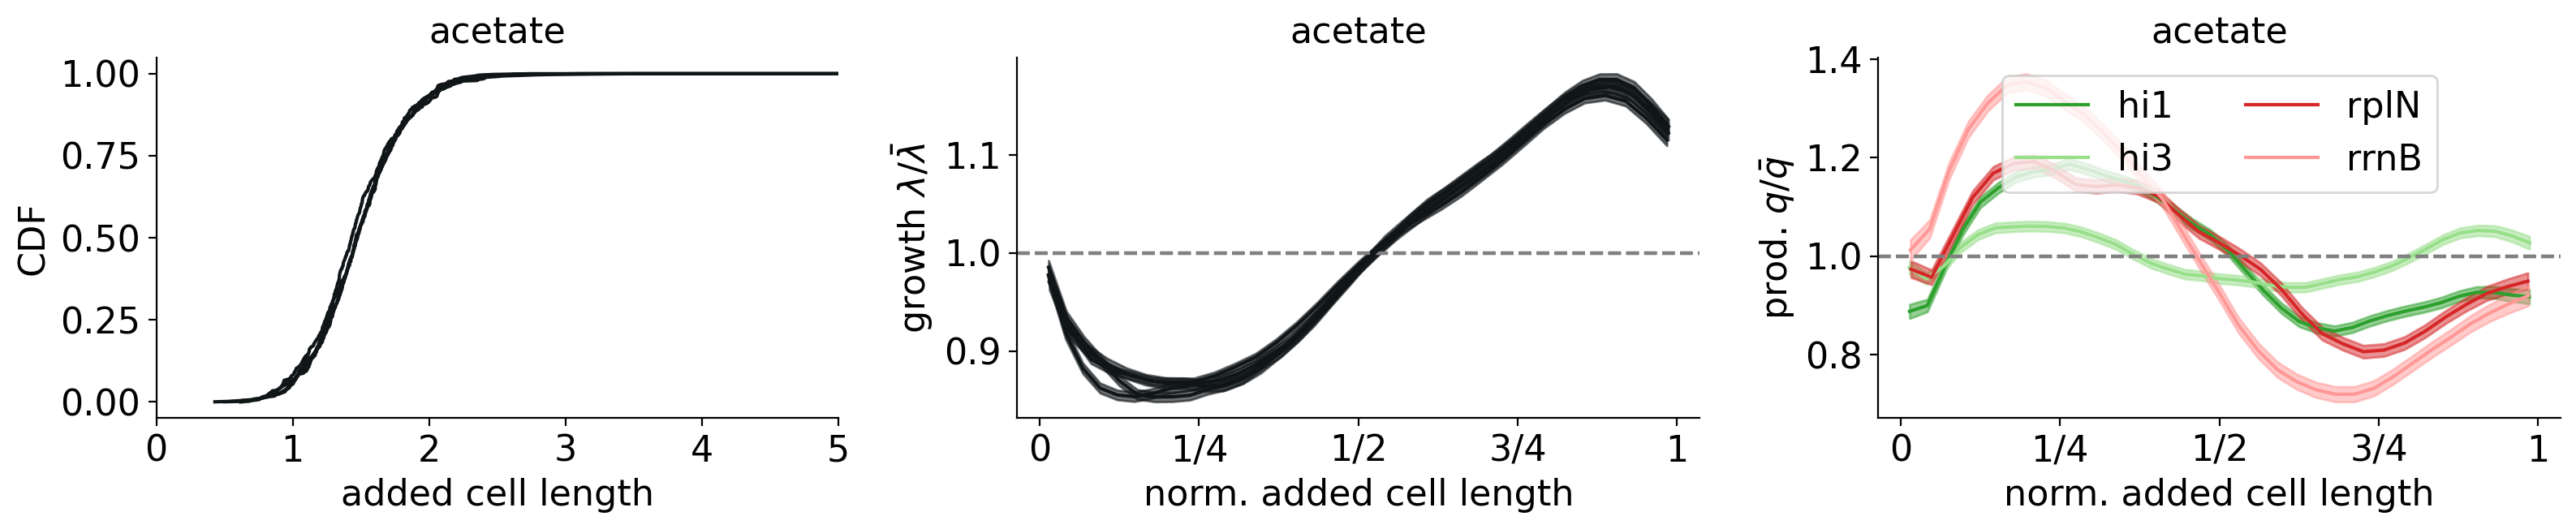

In [5]:
promoters_to_plot = ['hi1', 'hi3', 'rplN', 'rrnB']
legend=True

for condition in [conditions[0],conditions[1], conditions[2]]:
    files_in_condition = [file for file in prediction_files if condition in file.split("/")[-1] and file.split("/")[-1].split("_")[1] in promoters_to_plot]    
    # =========== cc =========== #
    
    added_volume_dependence(files_in_condition,  
                            # outfile=os.path.join("../../figures_for_method_paper/Figure4/", condition + "{:s}_norm_l_{:s}.pdf" ), 
                            show=False, 
                            norm_l=True, 
                            norm_q=True, 
                            xaxis_parameter="volume",
                            alignment="norm", 
                            interpolate="auto",
                            color_code="promoter",
                            label="promoter", 
                            legend=legend,
                            title = label_by_condition[condition] )

    break


Saved: ../../figures_for_method_paper/plots_main/cell_cycle/all_cellc_cycle_dependencies.pdf


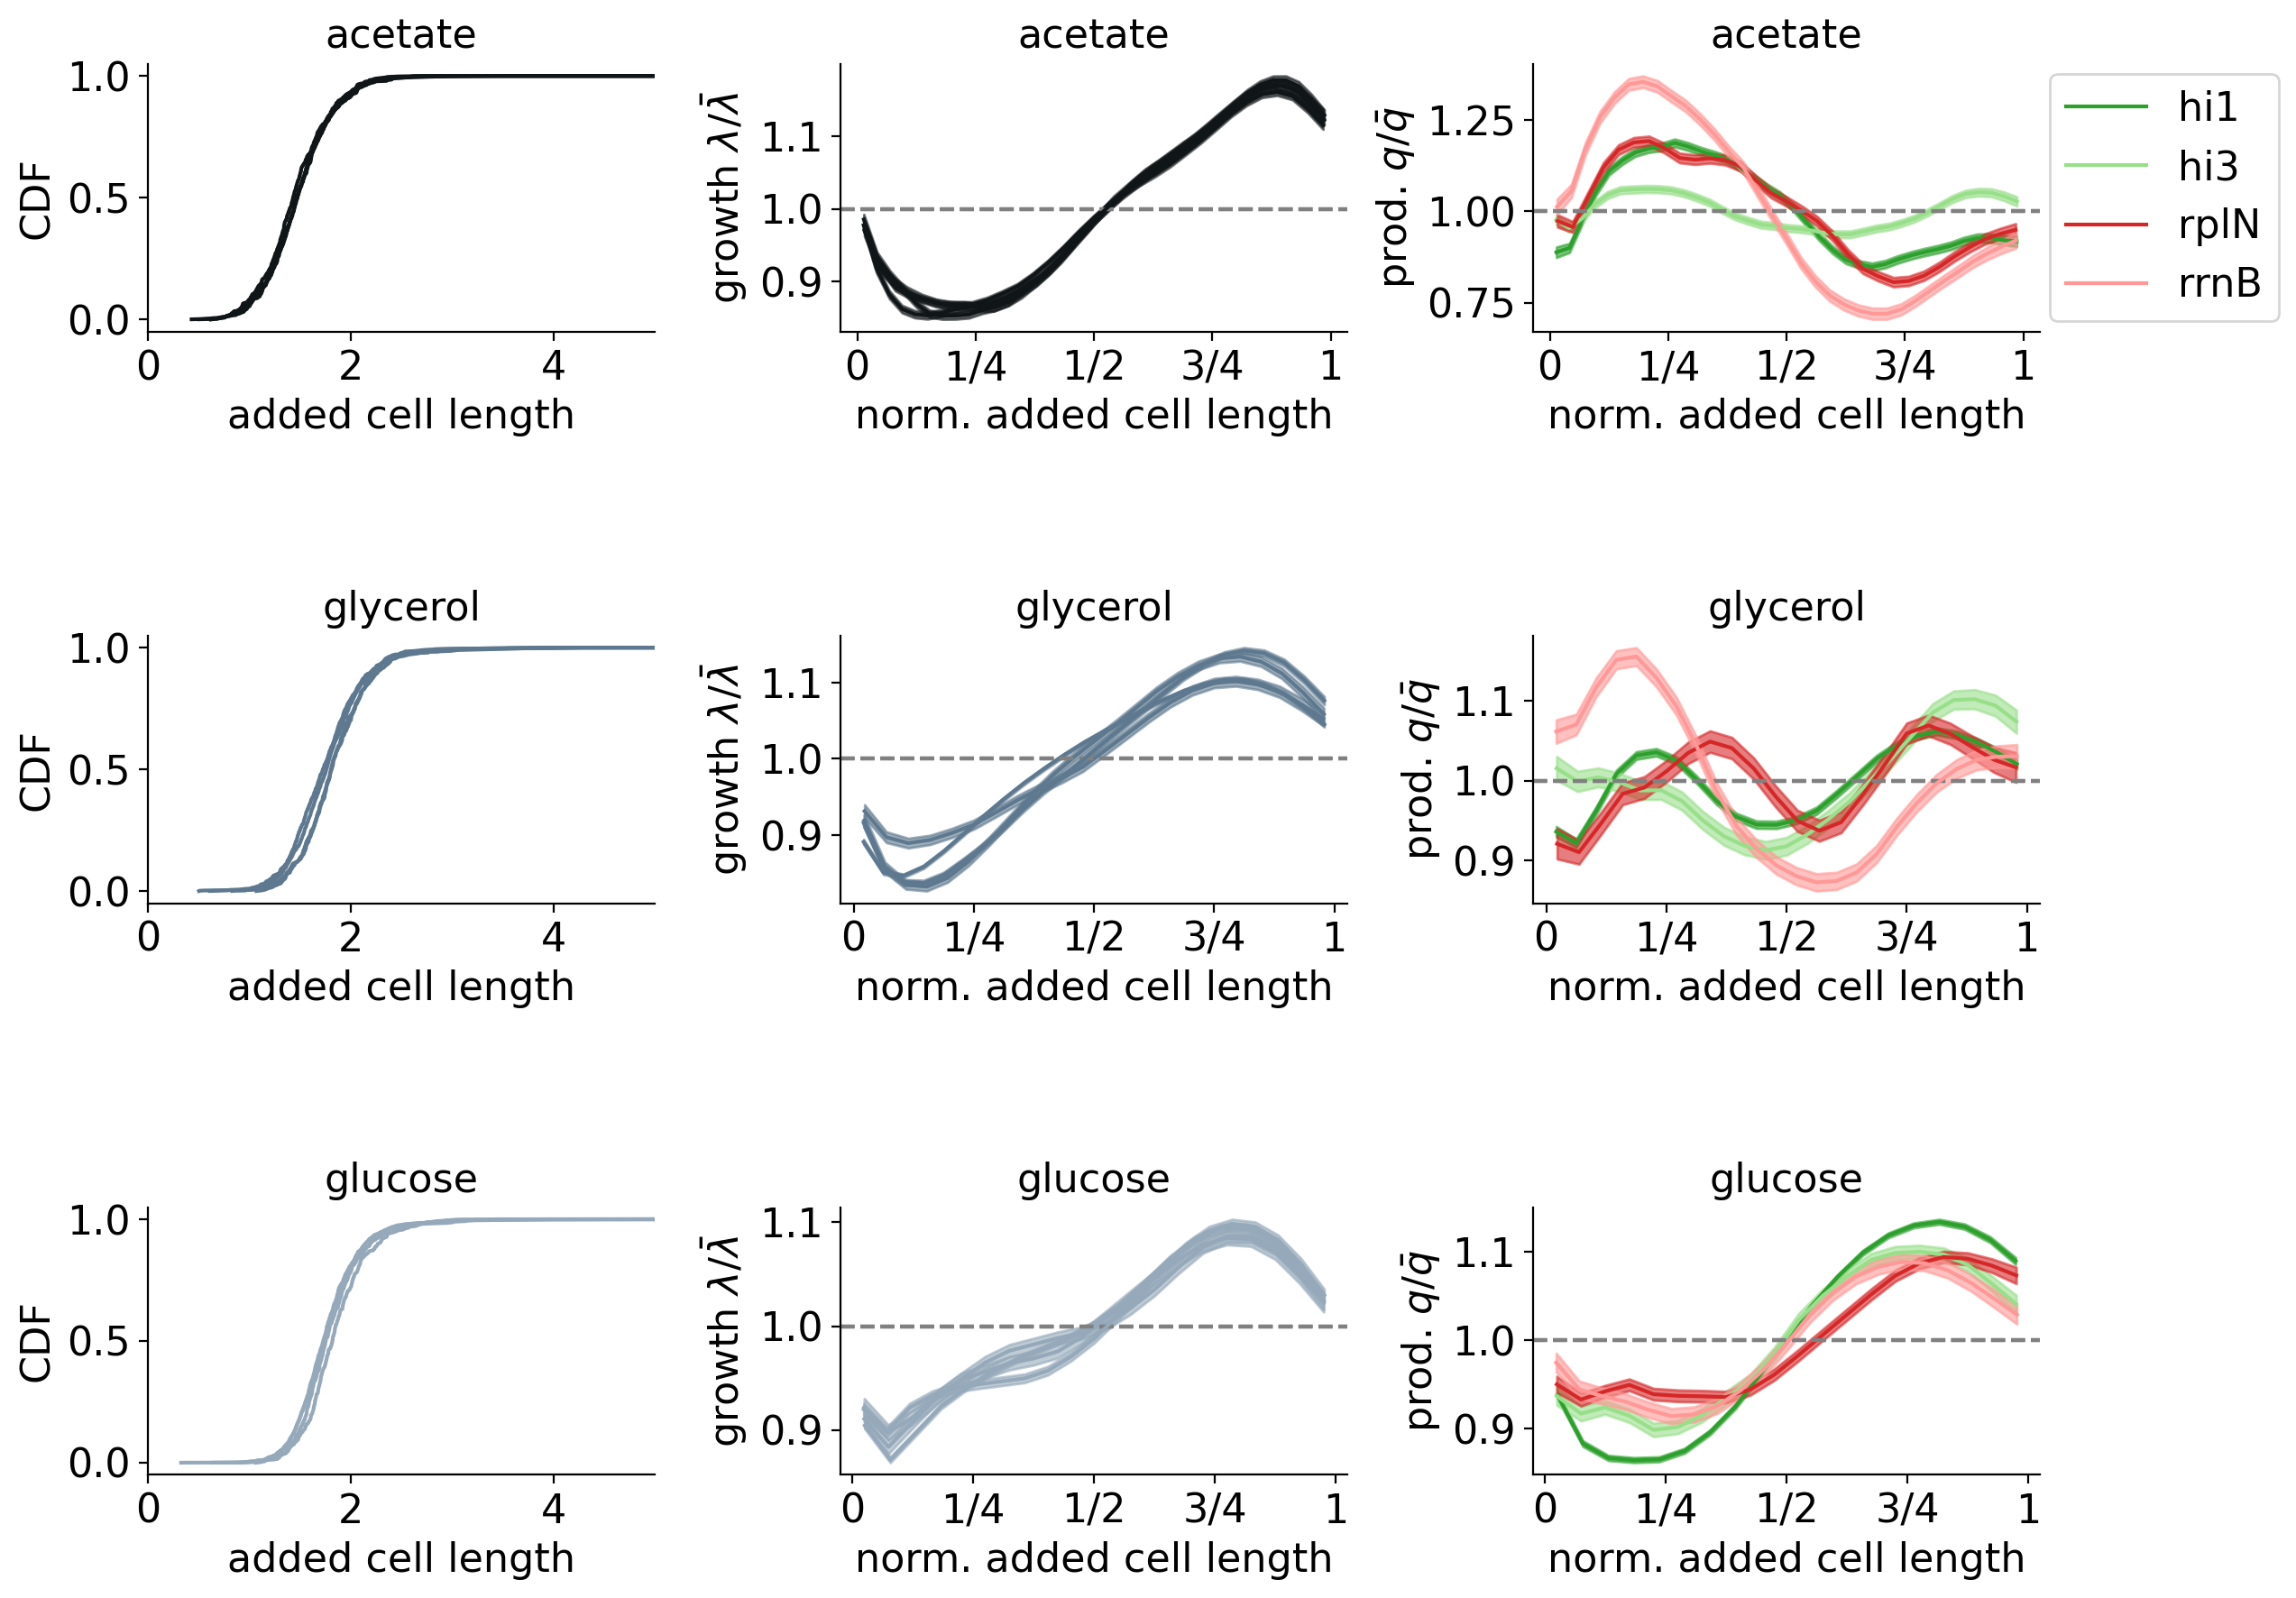

In [10]:
def added_volume_dependence_all(all_filenames,  
                            xlim=[None, None], 
                            ylim=[None, None],
                            hist_xlim=[None, None],
                            outfile=None, 
                            show=True, 
                            norm_q=False, 
                            norm_l=False,
                            plot_scatter=False,
                            plot_all=False,
                            xaxis_parameter="volume",
                            alignment="norm", 
                            growth_rate_unit=60,
                            label="both",
                            title=None,
                            interpolate=None,
                            color_code="condition", 
                            bins=10, 
                            show_cc_corr=False,
                           legend=True):
    
    """ needs a prediction file, start, stop, step refers to cells """

    fig, axes = plt.subplots(3, 3, figsize=(FULL_SIZE, FULL_SIZE*0.7))
    # axes = axes.transpose()
    
    for i, condition in enumerate(conditions[:3]):
        filenames = [file for file in all_filenames if condition in file.split("/")[-1]]    

        ax = axes[i,:]
        ax0b, ax0, ax1 = ax[0], ax[1], ax[2]
        
        for a in [ax0, ax1]:
            a.set_xticks(np.arange(0, 1.25, 0.25))
            a.set_xticklabels(["0", "1/4", "1/2", "3/4", "1"])
            
        for a in [ax0, ax1, ax0b]:
            a.set_title( label_by_condition[condition] )
            a.spines["top"].set_visible(False)
            a.spines["right"].set_visible(False)
            a.spines['right'].set_color('none')
            a.yaxis.tick_left()
            a.spines['top'].set_color('none')
            a.xaxis.tick_bottom()

        longest_cc = []

        for filename in filenames:
            data_set_name = re.split('_f\d', filename.split('/')[-1] )[0]
            condition = data_set_name.split("_")[0]
            promoter = data_set_name.split("_")[1]
            
            if i == 0:
                labeli = promoter
            else:
                labeli = None

            altcolor_by_promoter = {p: col for p,col  in zip(['hi1','hi3','rplN','rrnB'], ["#2ca02c" ,"#98df8a" ,"#d62728" ,"#ff9896"])}
            altcolor_by_condition = {cond: col for cond,col  in zip(conditions, ["#101518", "#5e798f", "#95a9ba", "#adbdc9" ])}

            condition_color = altcolor_by_condition[condition]
            promoter_color = altcolor_by_promoter[promoter]

            data = pd.read_csv(filename, skiprows=header_lines(filename))
            cells_data = df2ggp_cells(data)

            collect_mean_l = np.array([])
            collect_var_l = np.array([])

            collect_mean_q = np.array([])
            collect_var_q = np.array([])

            xaxis = np.array([])
            xaxis_cc = np.array([])
            if interpolate!=None:
                if interpolate=="auto":
                    n_d = 0
                    for cell in cells_data:
                        n_d += len(cell.time)
                    n_interpolate=int(n_d/len(cells_data))
                    bins=n_interpolate
                else:
                    n_interpolate = interpolate
                    bins=n_interpolate

            for _, cell in enumerate(cells_data):
                if len(cell.time)<2:
                    continue

                if xaxis_parameter == "volume":
                    single_cell_xaxis = np.exp(cell.mean_x)
                elif xaxis_parameter == "time":
                    single_cell_xaxis = np.array(cell.time)

                if alignment=="norm":                    
                    dx = (single_cell_xaxis -single_cell_xaxis[0])  \
                        / (single_cell_xaxis[-1] - single_cell_xaxis[0]) 

                elif alignment== "birth":
                    dx = single_cell_xaxis - single_cell_xaxis[0]
                else:
                    return

                if interpolate!=None:
                    linspace = np.linspace(dx[0], dx[-1], n_interpolate)
                    cell.mean_l=np.interp(linspace, dx, cell.mean_l)
                    cell.cov_ll=np.interp(linspace, dx, cell.cov_ll)

                    cell.mean_q=np.interp(linspace, dx, cell.mean_q)
                    cell.cov_qq=np.interp(linspace, dx, cell.cov_qq)
                    dx = linspace


                xaxis_cc = np.append(xaxis_cc, single_cell_xaxis[-1] - single_cell_xaxis[0])
                xaxis = np.append(xaxis, dx)

                collect_mean_l = np.append(collect_mean_l, cell.mean_l)
                collect_var_l = np.append(collect_var_l, cell.cov_ll)

                collect_mean_q = np.append(collect_mean_q, cell.mean_q)
                collect_var_q = np.append(collect_var_q, cell.cov_qq)

            mean_l, bin_edges,_ = stats.binned_statistic(xaxis, collect_mean_l,statistic='mean', bins=bins)
            sum_l, _,_   = stats.binned_statistic(xaxis, collect_var_l, statistic='sum', bins=bins)
            count_l, _,_   = stats.binned_statistic(xaxis, collect_var_l, statistic='count', bins=bins)
            std_l = np.sqrt(sum_l / count_l**2)

            if norm_l:
                ax0.axhline(1, color="grey", ls='--')
                normalization_l = np.mean(collect_mean_l)
                mean_l = mean_l/normalization_l
                std_l = std_l/normalization_l
                collect_mean_l/=normalization_l

            ## q
            mean_q, bin_edges,_ = stats.binned_statistic(xaxis, collect_mean_q,statistic='mean', bins=bins)
            sum_q, _,_   = stats.binned_statistic(xaxis, collect_var_q, statistic='sum', bins=bins)
            count_q, _,_   = stats.binned_statistic(xaxis, collect_var_q, statistic='count', bins=bins)

            std_q = np.sqrt(sum_q / count_q**2)
            if norm_q:
                ax1.axhline(1, color="grey", ls='--')
                normalization_q = np.mean(collect_mean_q)
                mean_q = mean_q/normalization_q
                std_q = std_q/normalization_q
                collect_mean_q = collect_mean_q/normalization_q

            ax0.plot(bin_edges[:-1]+np.diff(bin_edges)/2, mean_l, color=condition_color)
            ax0.fill_between(bin_edges[:-1]+np.diff(bin_edges)/2,
                             mean_l+std_l, 
                             mean_l-std_l, 
                             alpha=0.6, color=condition_color)


            ax1.plot(bin_edges[:-1]+np.diff(bin_edges)/2, 
                     mean_q, 
                     color=promoter_color, label=labeli)
            ax1.fill_between(bin_edges[:-1]+np.diff(bin_edges)/2, mean_q+std_q, mean_q-std_q, alpha=0.6, 
                             color=promoter_color)

            if plot_all:
                for _, cell in enumerate(cells_data):
                    if len(cell.time)<2:
                        continue

                    if xaxis_parameter == "volume":
                        single_cell_xaxis = np.exp(cell.mean_x)
                    elif xaxis_parameter == "time":
                        single_cell_xaxis = np.array(cell.time)

                    if alignment=="norm":                    
                        dx = (single_cell_xaxis -single_cell_xaxis[0])  \
                            / (single_cell_xaxis[-1] - single_cell_xaxis[0]) 

                    elif alignment== "birth":
                        dx = single_cell_xaxis - single_cell_xaxis[0]
                    else:
                        return

                    if interpolate!=None:
                        linspace = np.linspace(dx[0], dx[-1], n_interpolate)
                        dx = linspace
                    ax0.plot(dx, cell.mean_l/normalization_l, color="tab:grey", zorder=-10, alpha=0.05)
                    ax1.plot(dx, cell.mean_q/normalization_q, color="tab:grey", zorder=-10, alpha=0.05)

            ax0b.plot(np.append(np.sort(xaxis_cc), 10),np.append(np.linspace(0.0,1.0,len(xaxis_cc)), 1), color=condition_color)
            longest_cc.append(np.max(xaxis_cc))


        ax0b.set_xlim([0, 5])
        ax0b.set_ylabel("CDF")  
        ax0.set_ylabel(r"growth $\lambda/\bar{\lambda}$")   
        ax1.set_ylabel(r"prod. $q/\bar{q}$")   

        if i==0:
            # ax1.legend(loc='upper right', bbox_to_anchor=(1,1.1), ncol=2,  title_fontsize=MEDIUM_SIZE)
            ax1.legend(loc='center left', bbox_to_anchor=(0.98, 0.5), ncol=1,  title_fontsize=MEDIUM_SIZE)

        ax0b.set_xlabel("added cell length")  
        ax0.set_xlabel("norm. added cell length")  
        ax1.set_xlabel("norm. added cell length")  

    fig.tight_layout(h_pad=4)

    if outfile != None:
        fig.savefig(outfile.format(xaxis_parameter, alignment), dpi=600, facecolor="white", bbox_inches="tight")
        print("Saved:", outfile)
        plt.show()
        
        plt.close('all')
    elif show:
        plt.show()
    else:
        return ax
# ==================================================== #

promoters_to_plot = ['hi1', 'hi3', 'rplN', 'rrnB']

files_for_plot = [file for file in prediction_files \
                  if  file.split("/")[-1].split("_")[0] in [conditions[0],conditions[1], conditions[2]] \
                  and file.split("/")[-1].split("_")[1] in promoters_to_plot]    
    # =========== cc =========== #
    
added_volume_dependence_all(files_for_plot,  
                            outfile=os.path.join("../../figures_for_method_paper/plots_main/cell_cycle/all_cellc_cycle_dependencies.pdf" ), 
                            show=False, 
                            norm_l=True, 
                            norm_q=True, 
                            xaxis_parameter="volume",
                            alignment="norm", 
                            interpolate="auto",
                            color_code="promoter",
                            label="promoter", 
                            legend=True,
                            title = label_by_condition[condition] )


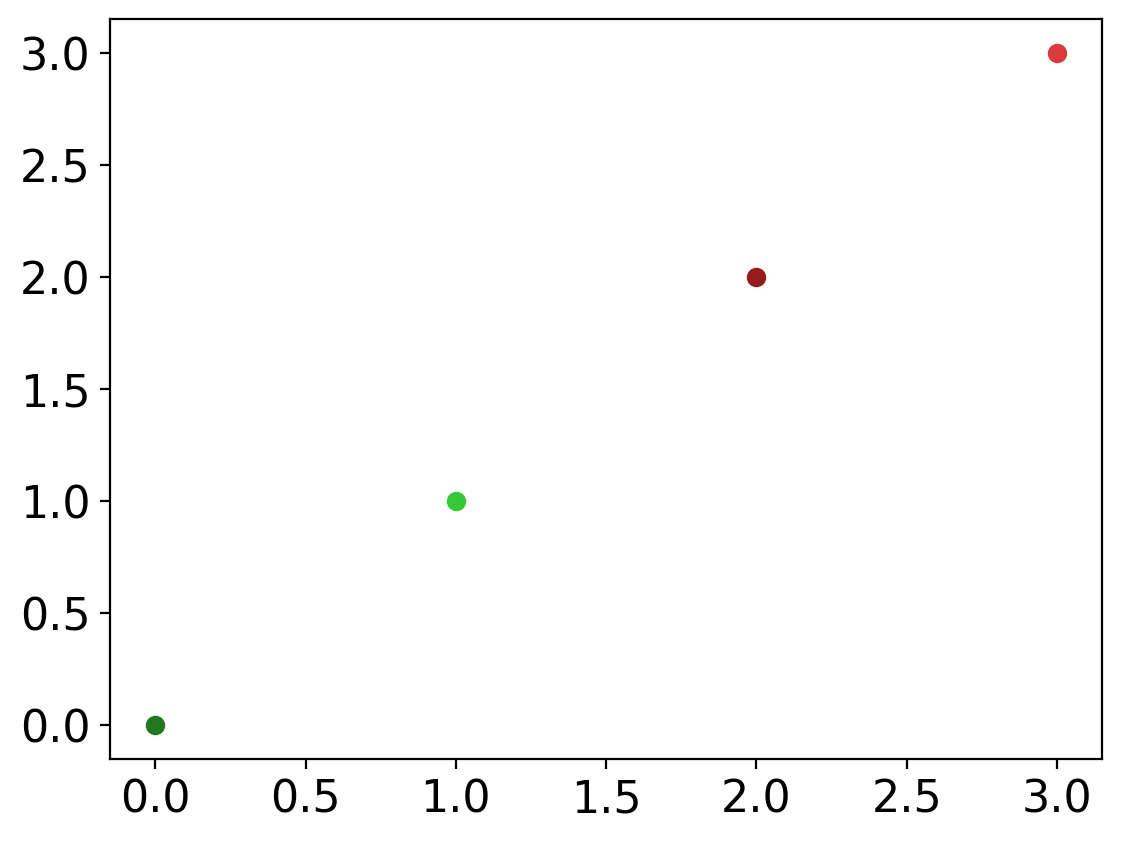

In [11]:
# altcolor_by_promoter = {p: col for p,col  in zip(['hi1','hi3','rplN','rrnB'], 
#                                                  ["#2ca02c" ,"#98df8a" ,"#d62728" ,"#ff9896"])}

cmapc = matplotlib.cm.get_cmap('tab20c')

altcolor_by_promoter = {p: col for p,col  in zip(['hi1','hi3','rplN','rrnB'], 
                                                 ["#217821" ,"#37c837" ,
                                                  "#951b1c" ,"#db3b3c"])}
altcolor_by_condition = {c: col for c,col  in zip(conditions, 
                                                 ["#101518", "#5e798f", "#95a9ba", "#adbdc9" ])}


for i, p in enumerate(['hi1','hi3','rplN','rrnB']):
    plt.scatter(i,i, color=altcolor_by_promoter[p])

Saved: ../../figures_for_method_paper/plots_main/cell_cycle/all_cellc_cycle_dependencies.pdf


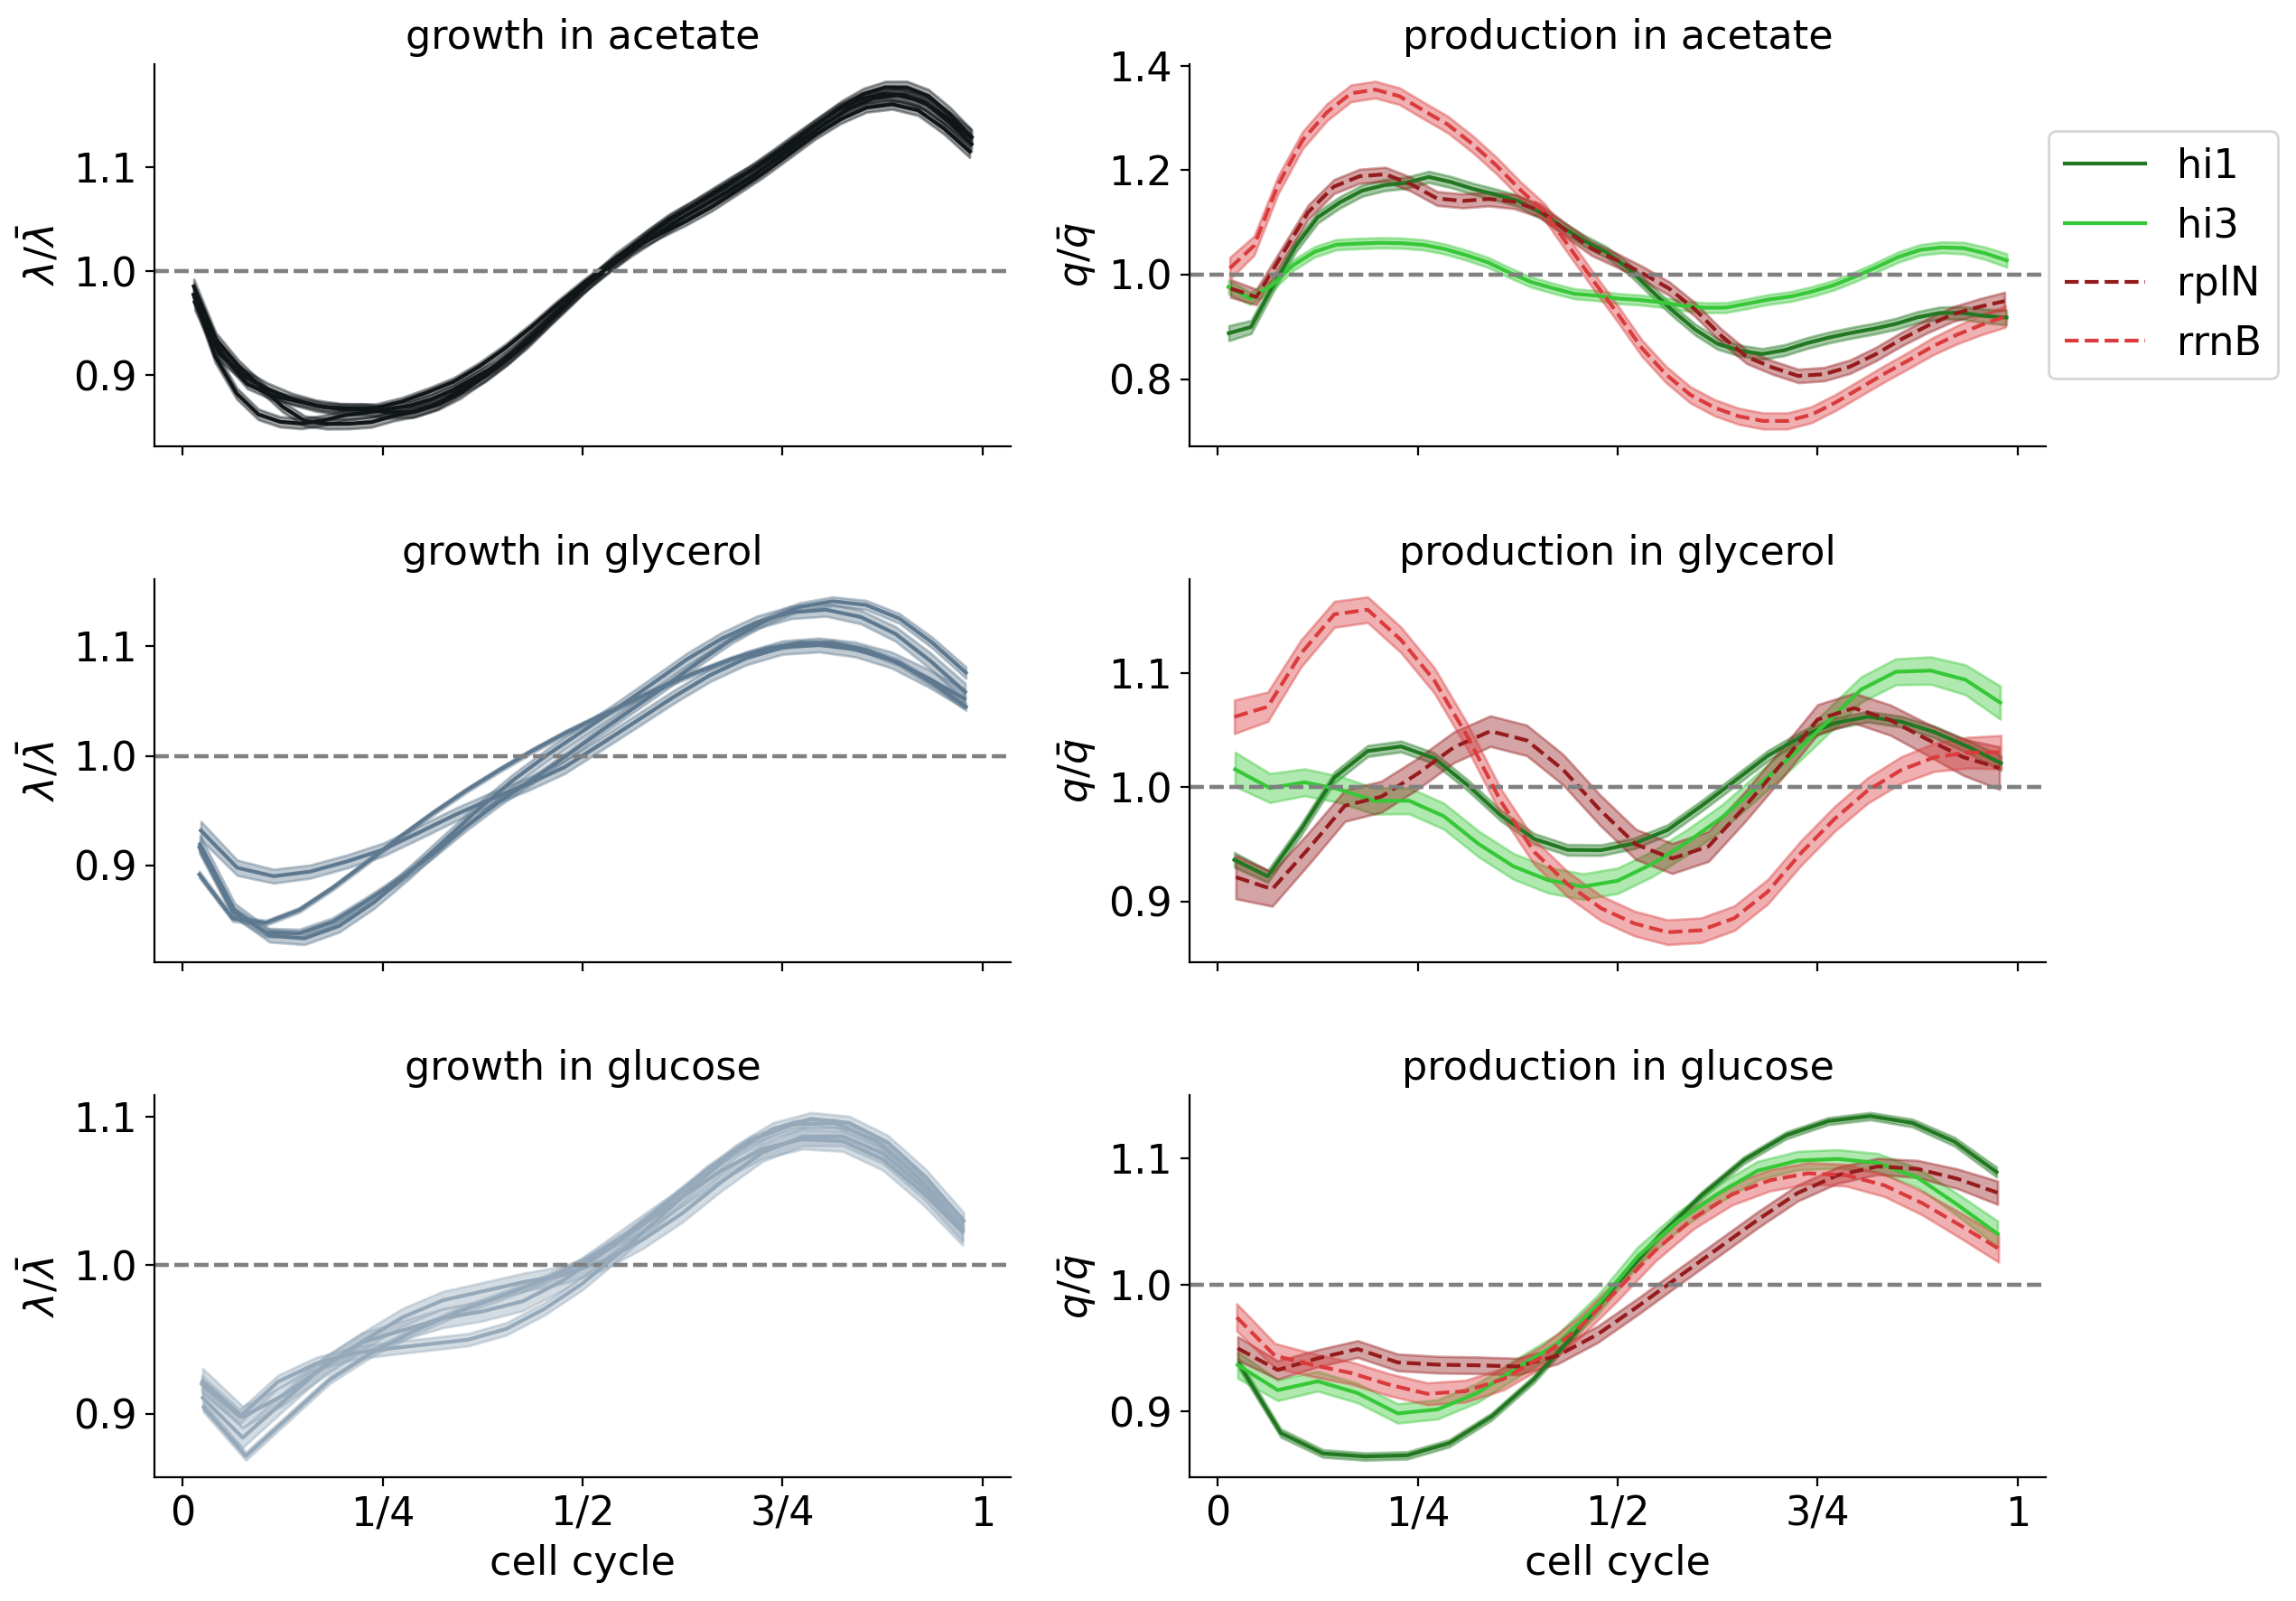

In [12]:
def added_volume_dependence_all_without_cdf(all_filenames,  
                            xlim=[None, None], 
                            ylim=[None, None],
                            hist_xlim=[None, None],
                            outfile=None, 
                            show=True, 
                            norm_q=False, 
                            norm_l=False,
                            plot_scatter=False,
                            plot_all=False,
                            xaxis_parameter="volume",
                            alignment="norm", 
                            growth_rate_unit=60,
                            label="both",
                            title=None,
                            interpolate=None,
                            color_code="condition", 
                            bins=10, 
                            show_cc_corr=False,
                           legend=True):
    
    """ needs a prediction file, start, stop, step refers to cells """

    fig, axes = plt.subplots(3,2, figsize=(FULL_SIZE, FULL_SIZE*0.7), sharex=True)
    
    for i, condition in enumerate(conditions[:3]):
        filenames = [file for file in all_filenames if condition in file.split("/")[-1]]    

        ax = axes[i,:]
        ax0, ax1 = ax[0], ax[1]
        ax0.set_title( "growth in " + label_by_condition[condition] )
        ax1.set_title( "production in " + label_by_condition[condition] )
                   
            
        for a in [ax0, ax1]:
            a.spines["top"].set_visible(False)
            a.spines["right"].set_visible(False)
            a.spines['right'].set_color('none')
            a.yaxis.tick_left()
            a.spines['top'].set_color('none')
            a.xaxis.tick_bottom()

        longest_cc = []

        for filename in filenames:
            data_set_name = re.split('_f\d', filename.split('/')[-1] )[0]
            condition = data_set_name.split("_")[0]
            promoter = data_set_name.split("_")[1]
            
            if i == 0:
                labeli = promoter
            else:
                labeli = None
    
            condition_color = altcolor_by_condition[condition]
            promoter_color = altcolor_by_promoter[promoter]

            data = pd.read_csv(filename, skiprows=header_lines(filename))
            cells_data = df2ggp_cells(data)

            collect_mean_l = np.array([])
            collect_var_l = np.array([])

            collect_mean_q = np.array([])
            collect_var_q = np.array([])

            xaxis = np.array([])
            xaxis_cc = np.array([])
            if interpolate!=None:
                if interpolate=="auto":
                    n_d = 0
                    for cell in cells_data:
                        n_d += len(cell.time)
                    n_interpolate=int(n_d/len(cells_data))
                    bins=n_interpolate
                else:
                    n_interpolate = interpolate
                    bins=n_interpolate

            for _, cell in enumerate(cells_data):
                if len(cell.time)<2:
                    continue

                if xaxis_parameter == "volume":
                    single_cell_xaxis = np.exp(cell.mean_x)
                elif xaxis_parameter == "time":
                    single_cell_xaxis = np.array(cell.time)

                if alignment=="norm":                    
                    dx = (single_cell_xaxis -single_cell_xaxis[0])  \
                        / (single_cell_xaxis[-1] - single_cell_xaxis[0]) 

                elif alignment== "birth":
                    dx = single_cell_xaxis - single_cell_xaxis[0]
                else:
                    return

                if interpolate!=None:
                    linspace = np.linspace(dx[0], dx[-1], n_interpolate)
                    cell.mean_l=np.interp(linspace, dx, cell.mean_l)
                    cell.cov_ll=np.interp(linspace, dx, cell.cov_ll)

                    cell.mean_q=np.interp(linspace, dx, cell.mean_q)
                    cell.cov_qq=np.interp(linspace, dx, cell.cov_qq)
                    dx = linspace


                xaxis_cc = np.append(xaxis_cc, single_cell_xaxis[-1] - single_cell_xaxis[0])
                xaxis = np.append(xaxis, dx)

                collect_mean_l = np.append(collect_mean_l, cell.mean_l)
                collect_var_l = np.append(collect_var_l, cell.cov_ll)

                collect_mean_q = np.append(collect_mean_q, cell.mean_q)
                collect_var_q = np.append(collect_var_q, cell.cov_qq)

            mean_l, bin_edges,_ = stats.binned_statistic(xaxis, collect_mean_l,statistic='mean', bins=bins)
            sum_l, _,_   = stats.binned_statistic(xaxis, collect_var_l, statistic='sum', bins=bins)
            count_l, _,_   = stats.binned_statistic(xaxis, collect_var_l, statistic='count', bins=bins)
            std_l = np.sqrt(sum_l / count_l**2)

            if norm_l:
                ax0.axhline(1, color="grey", ls='--')
                normalization_l = np.mean(collect_mean_l)
                mean_l = mean_l/normalization_l
                std_l = std_l/normalization_l
                collect_mean_l/=normalization_l

            ## q
            mean_q, bin_edges,_ = stats.binned_statistic(xaxis, collect_mean_q,statistic='mean', bins=bins)
            sum_q, _,_   = stats.binned_statistic(xaxis, collect_var_q, statistic='sum', bins=bins)
            count_q, _,_   = stats.binned_statistic(xaxis, collect_var_q, statistic='count', bins=bins)

            std_q = np.sqrt(sum_q / count_q**2)
            if norm_q:
                ax1.axhline(1, color="grey", ls='--')
                normalization_q = np.mean(collect_mean_q)
                mean_q = mean_q/normalization_q
                std_q = std_q/normalization_q
                collect_mean_q = collect_mean_q/normalization_q

            ax0.plot(bin_edges[:-1]+np.diff(bin_edges)/2, mean_l, color=condition_color)
            ax0.fill_between(bin_edges[:-1]+np.diff(bin_edges)/2,
                             mean_l+std_l, 
                             mean_l-std_l, 
                             alpha=0.4, color=condition_color)
            
            # approx. points per 0.25 cell cycle 
            # print("mean_l", np.min(mean_l), np.max(mean_l))
            # print("mean_q", np.min(mean_q), np.max(mean_q))
            if promoter[0]=="r":
                ls="--"
            else:
                ls="-"
            ax1.plot(bin_edges[:-1]+np.diff(bin_edges)/2, 
                     mean_q, 
                     color=promoter_color, 
                     label=labeli,
                    ls=ls)
            ax1.fill_between(bin_edges[:-1]+np.diff(bin_edges)/2, mean_q+std_q, mean_q-std_q, alpha=0.4, 
                             color=promoter_color)

            if plot_all:
                for _, cell in enumerate(cells_data):
                    if len(cell.time)<2:
                        continue

                    if xaxis_parameter == "volume":
                        single_cell_xaxis = np.exp(cell.mean_x)
                    elif xaxis_parameter == "time":
                        single_cell_xaxis = np.array(cell.time)

                    if alignment=="norm":                    
                        dx = (single_cell_xaxis -single_cell_xaxis[0])  \
                            / (single_cell_xaxis[-1] - single_cell_xaxis[0]) 

                    elif alignment== "birth":
                        dx = single_cell_xaxis - single_cell_xaxis[0]
                    else:
                        return

                    if interpolate!=None:
                        linspace = np.linspace(dx[0], dx[-1], n_interpolate)
                        dx = linspace
                    ax0.plot(dx, cell.mean_l/normalization_l, color="tab:grey", zorder=-10, alpha=0.05)
                    ax1.plot(dx, cell.mean_q/normalization_q, color="tab:grey", zorder=-10, alpha=0.05)

        ax0.set_ylabel(r"$\lambda/\bar{\lambda}$")   
        ax1.set_ylabel(r"$q/\bar{q}$")   

        if i==0:
            # ax1.legend(loc='upper right', bbox_to_anchor=(1,1.1), ncol=2,  title_fontsize=MEDIUM_SIZE)
            ax1.legend(loc='center left', bbox_to_anchor=(0.98, 0.5), ncol=1,  title_fontsize=MEDIUM_SIZE)
        if i==2:
            for a in [ax0, ax1]:
                a.set_xlabel("cell cycle")  
                a.set_xticks(np.arange(0, 1.25, 0.25))
                a.set_xticklabels(["0", "1/4", "1/2", "3/4", "1"])

    fig.tight_layout(h_pad=2)

    if outfile != None:
        fig.savefig(outfile.format(xaxis_parameter, alignment), dpi=600, facecolor="white", bbox_inches="tight")
        print("Saved:", outfile)
        plt.show()
        
        plt.close('all')
    elif show:
        plt.show()
    else:
        return ax
# ==================================================== #

promoters_to_plot = ['hi1', 'hi3', 'rplN', 'rrnB']

files_for_plot = [file for file in prediction_files \
                  if  file.split("/")[-1].split("_")[0] in [conditions[0],conditions[1], conditions[2]] \
                  and file.split("/")[-1].split("_")[1] in promoters_to_plot]    
    # =========== cc =========== #
    
added_volume_dependence_all_without_cdf(files_for_plot,  
                                outfile=os.path.join("../../figures_for_method_paper/plots_main/cell_cycle/all_cellc_cycle_dependencies.pdf" ), 
                                show=False, 
                                norm_l=True, 
                                norm_q=True, 
                                xaxis_parameter="volume",
                                alignment="norm", 
                                interpolate="auto",
                                color_code="promoter",
                                label="promoter", 
                                legend=True)




Saved: ../../figures_for_method_paper/supp/supp_cell_cycle/all_cellc_cycle_dependencies_time_parametrization.pdf


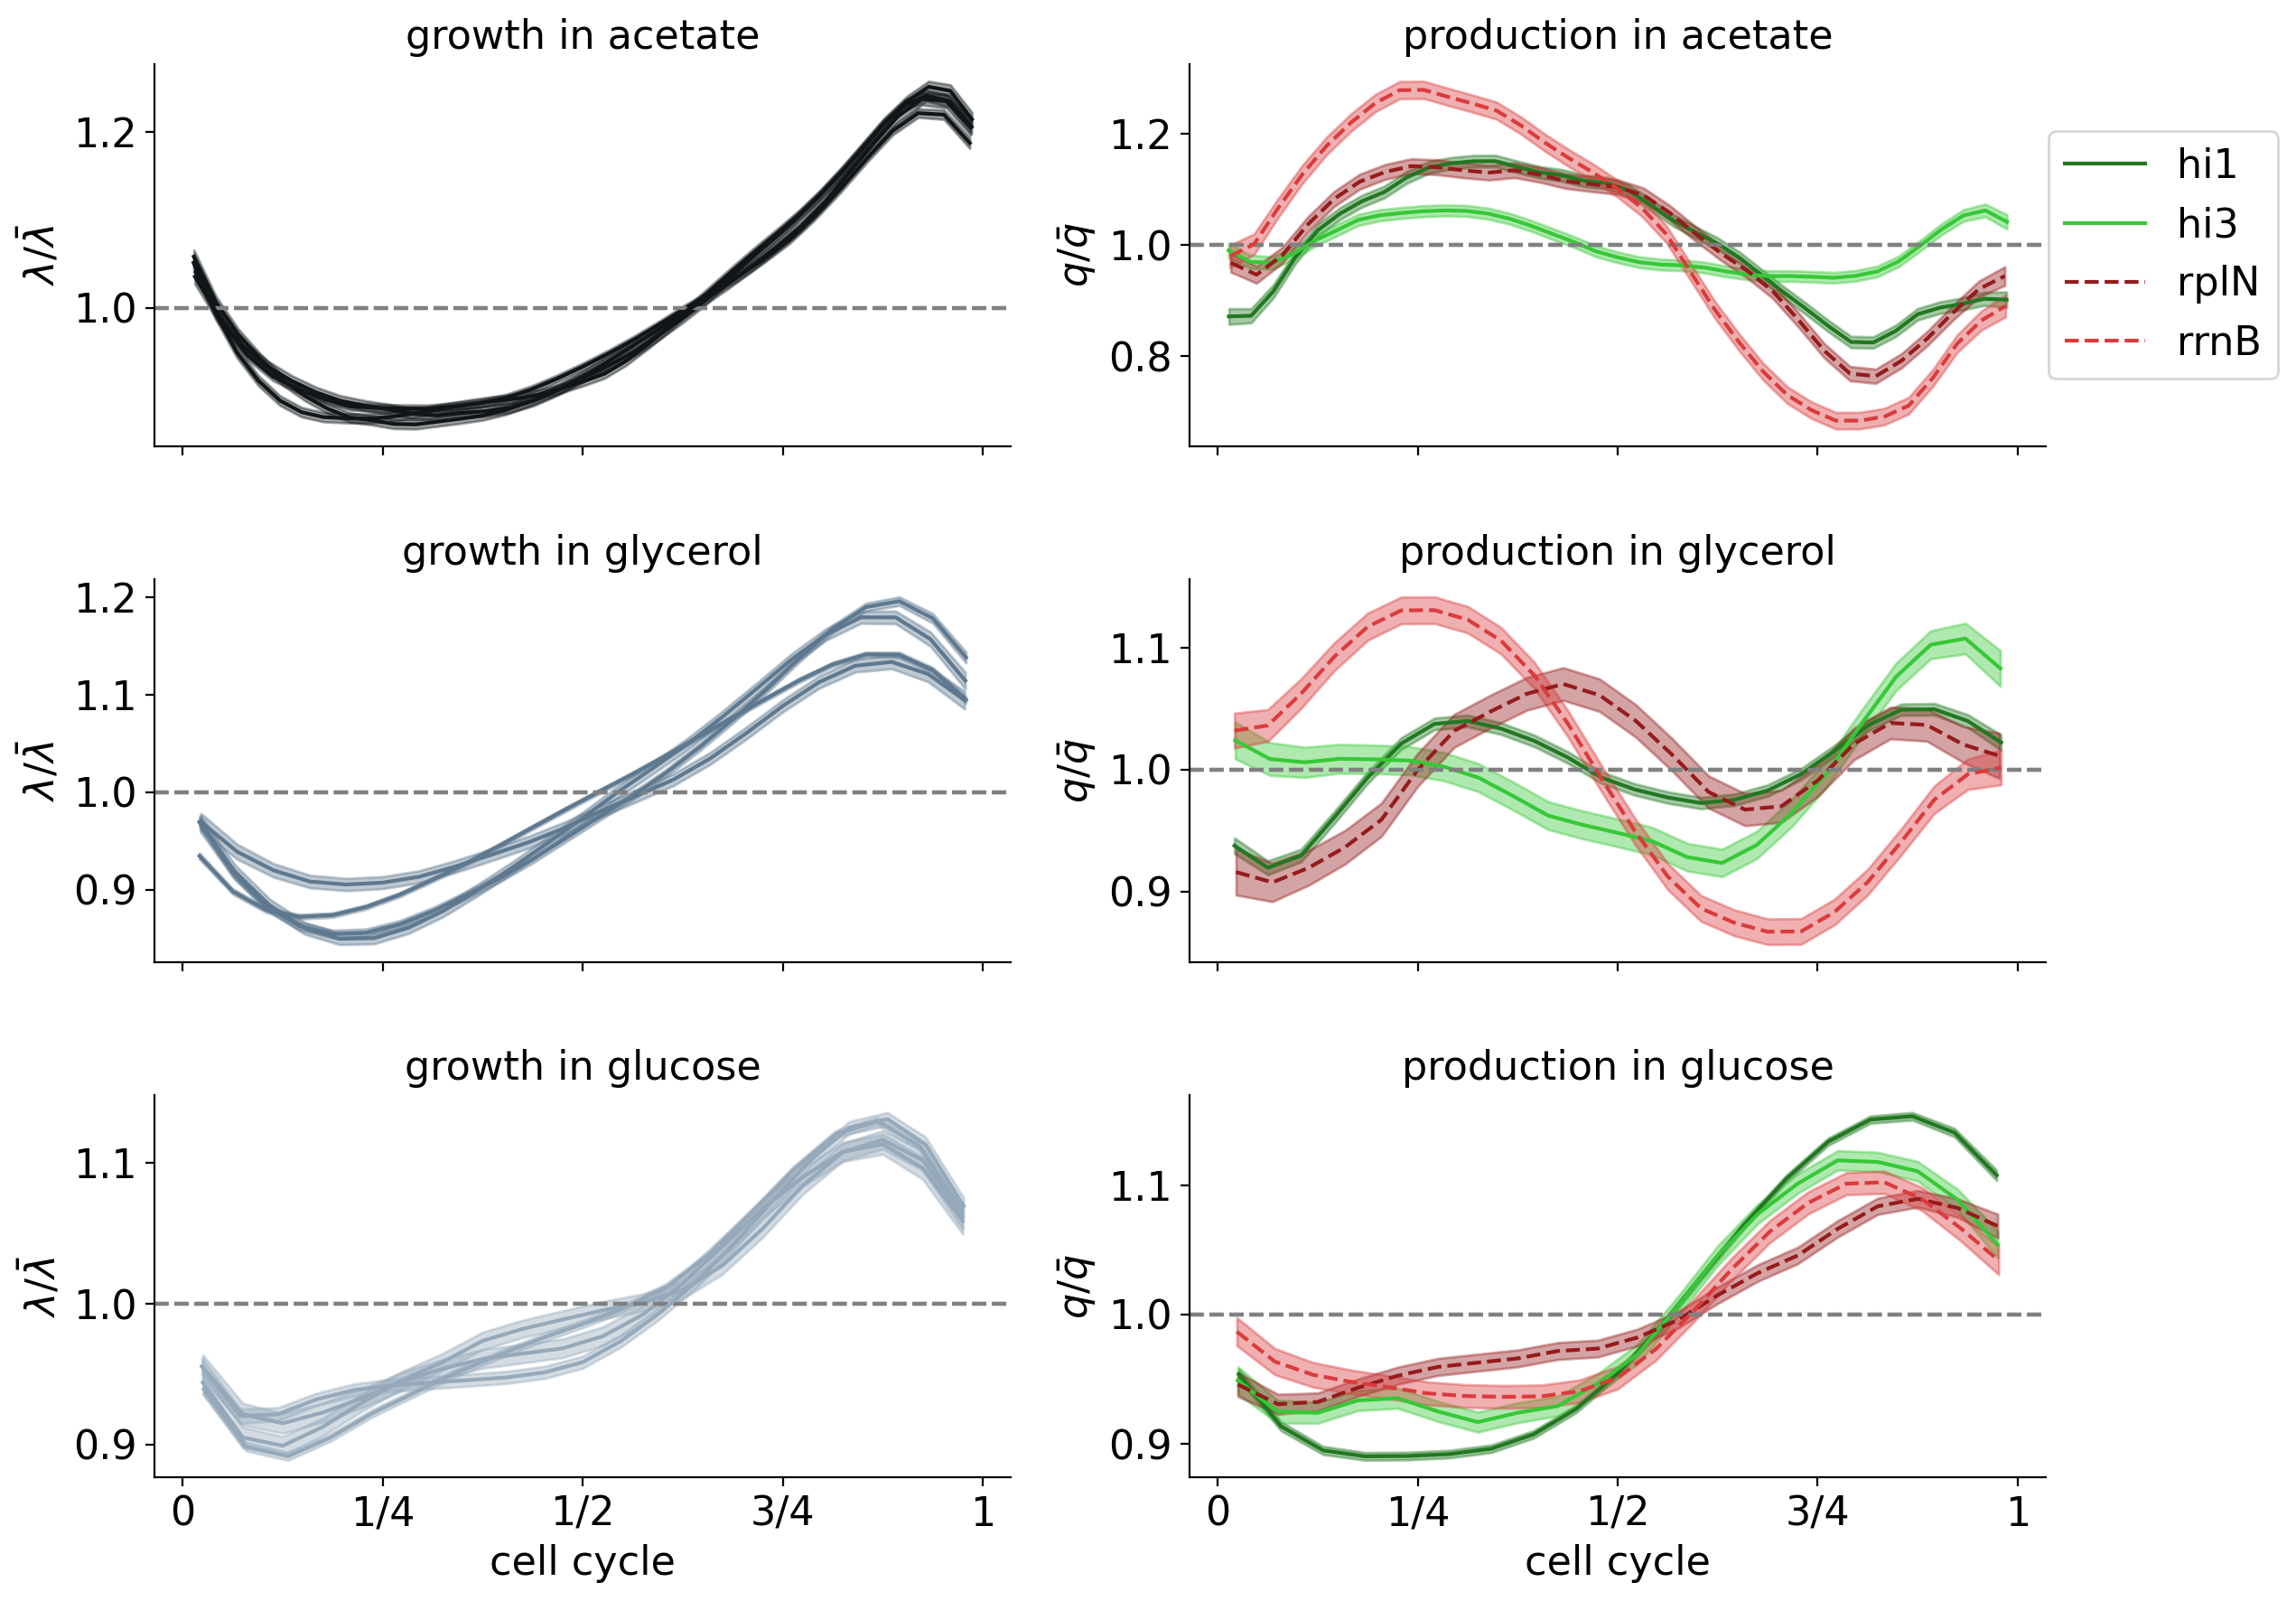

In [13]:
   
added_volume_dependence_all_without_cdf(files_for_plot,  
                                outfile=os.path.join("../../figures_for_method_paper/supp/supp_cell_cycle/all_cellc_cycle_dependencies_time_parametrization.pdf" ), 
                                show=False, 
                                norm_l=True, 
                                norm_q=True, 
                                xaxis_parameter="time",
                                alignment="norm", 
                                interpolate="auto",
                                color_code="promoter",
                                label="promoter", 
                                legend=True,
                                title = label_by_condition[condition] )

Saved: ../../figures_for_method_paper/supp/supp_cell_cycle/acetate_cc.pdf


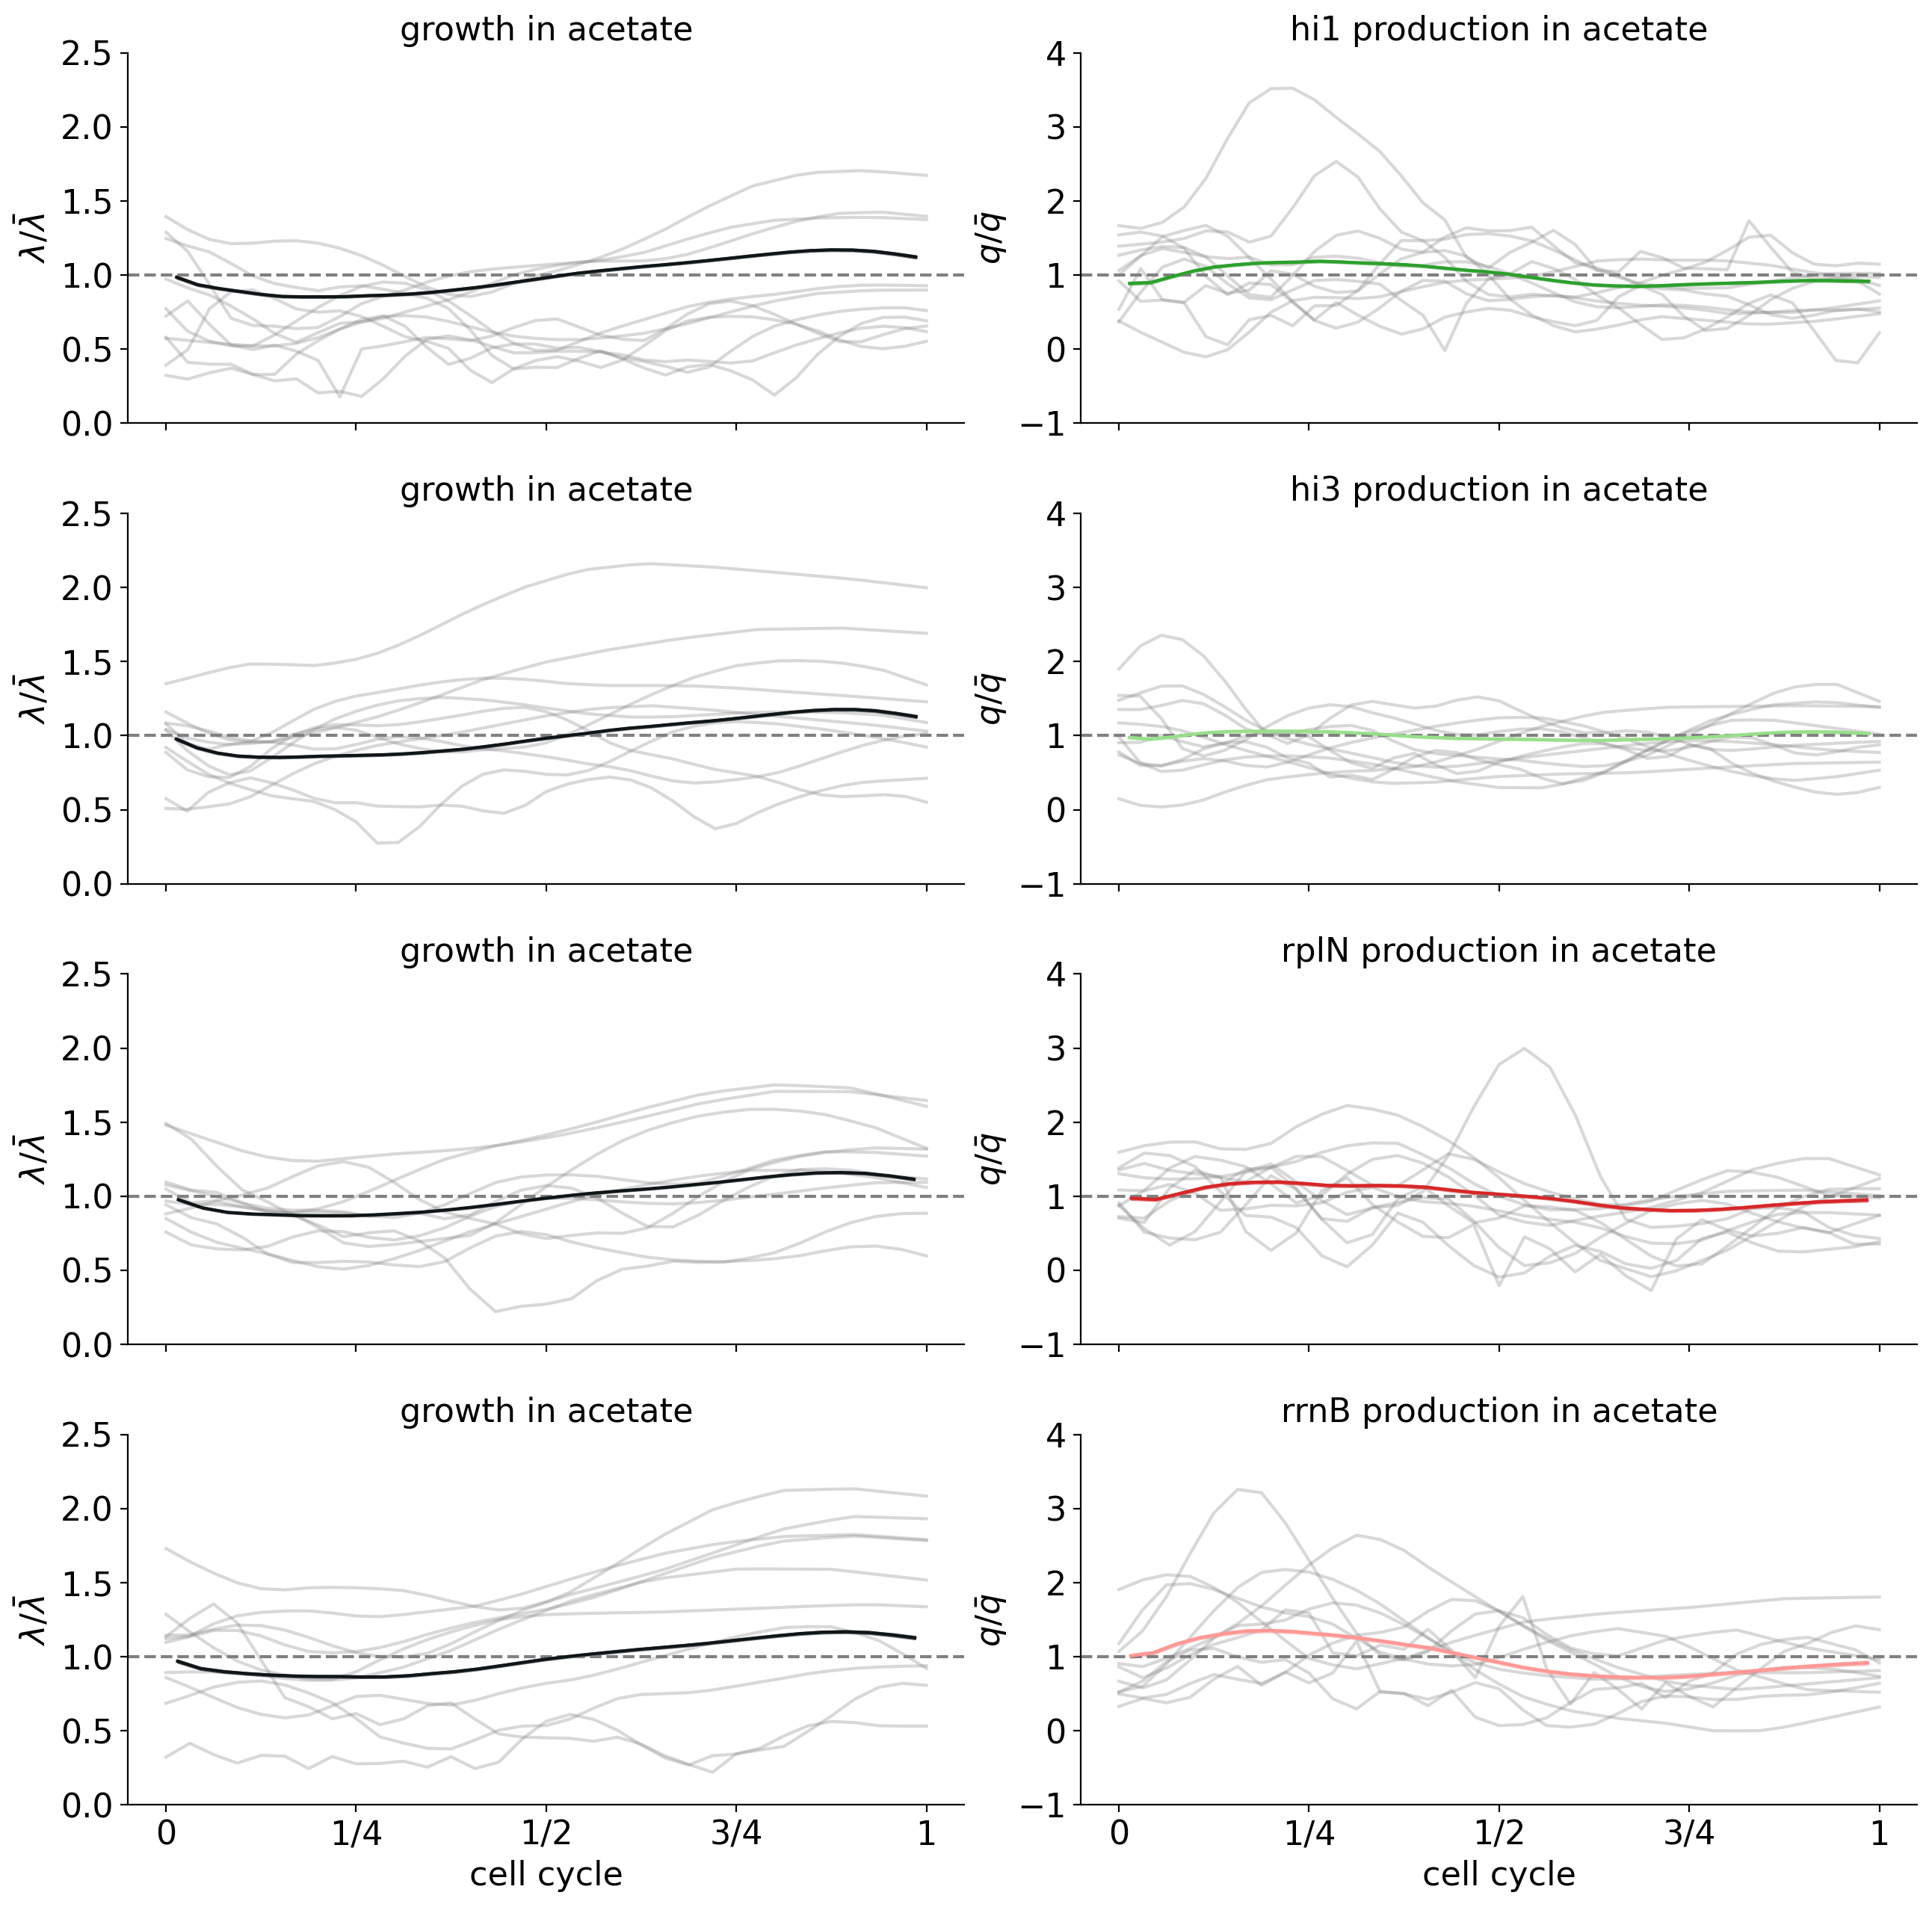

Saved: ../../figures_for_method_paper/supp/supp_cell_cycle/glycerol_cc.pdf


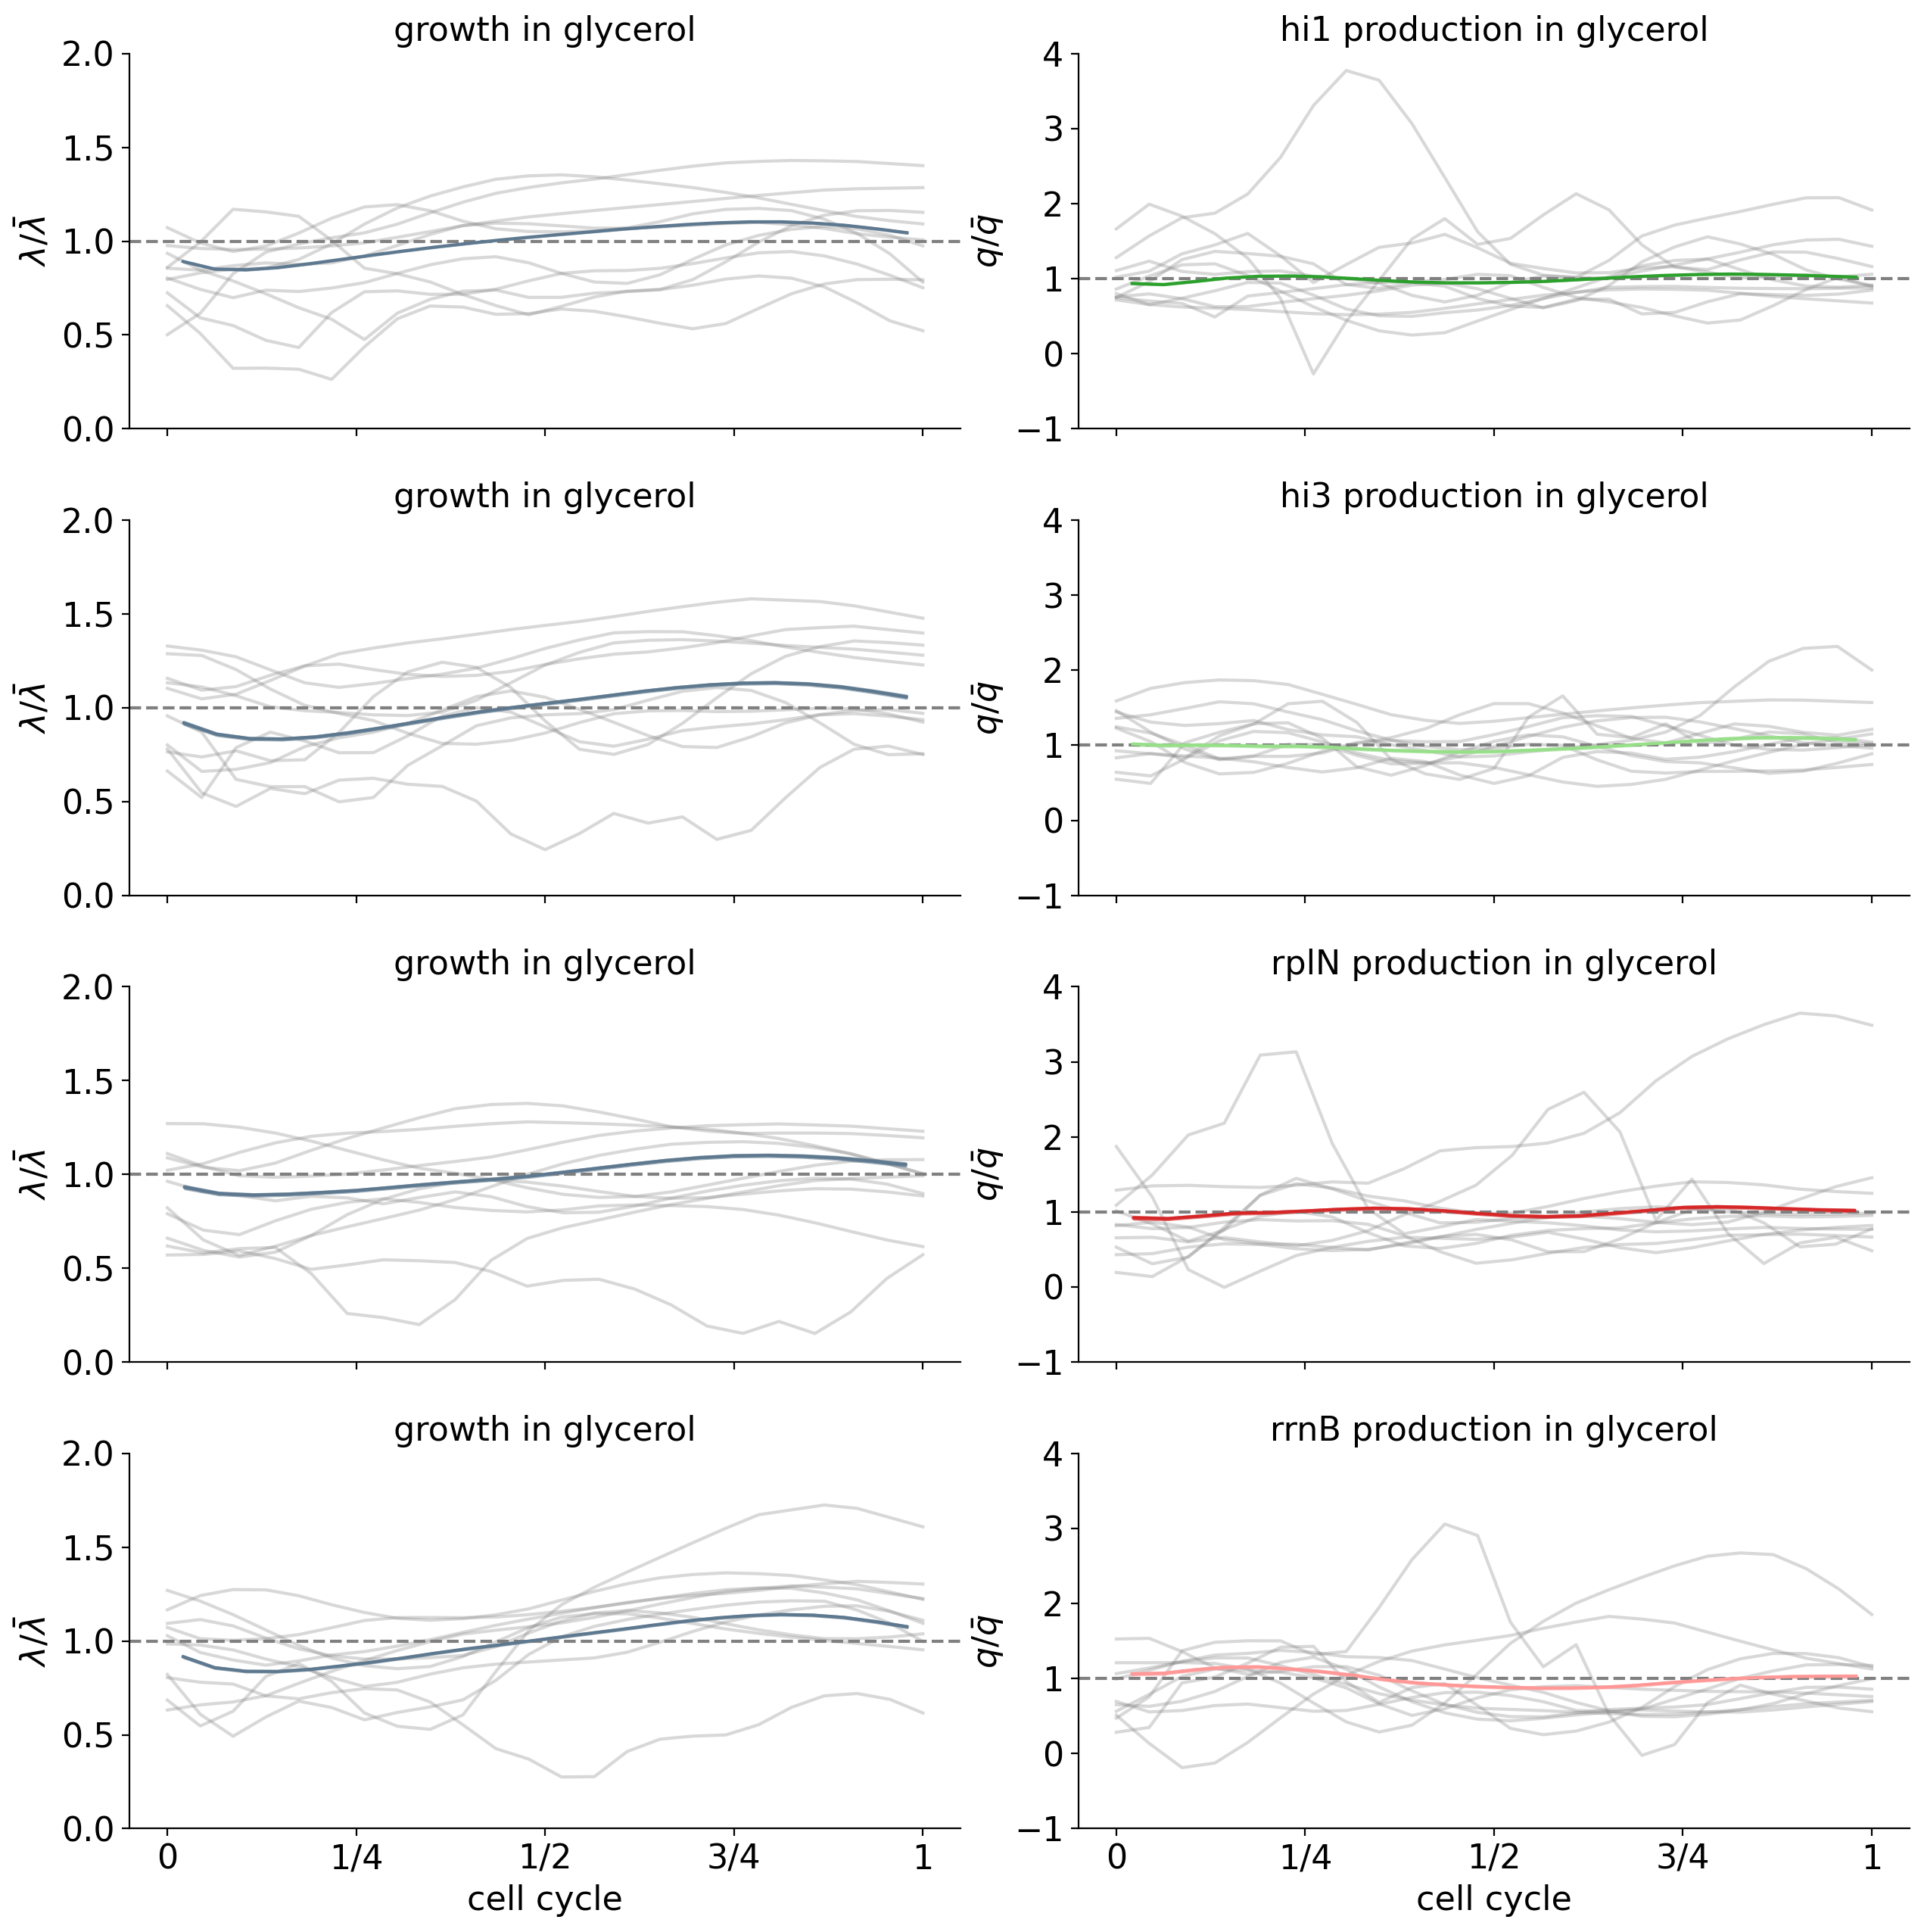

Saved: ../../figures_for_method_paper/supp/supp_cell_cycle/glucose_cc.pdf


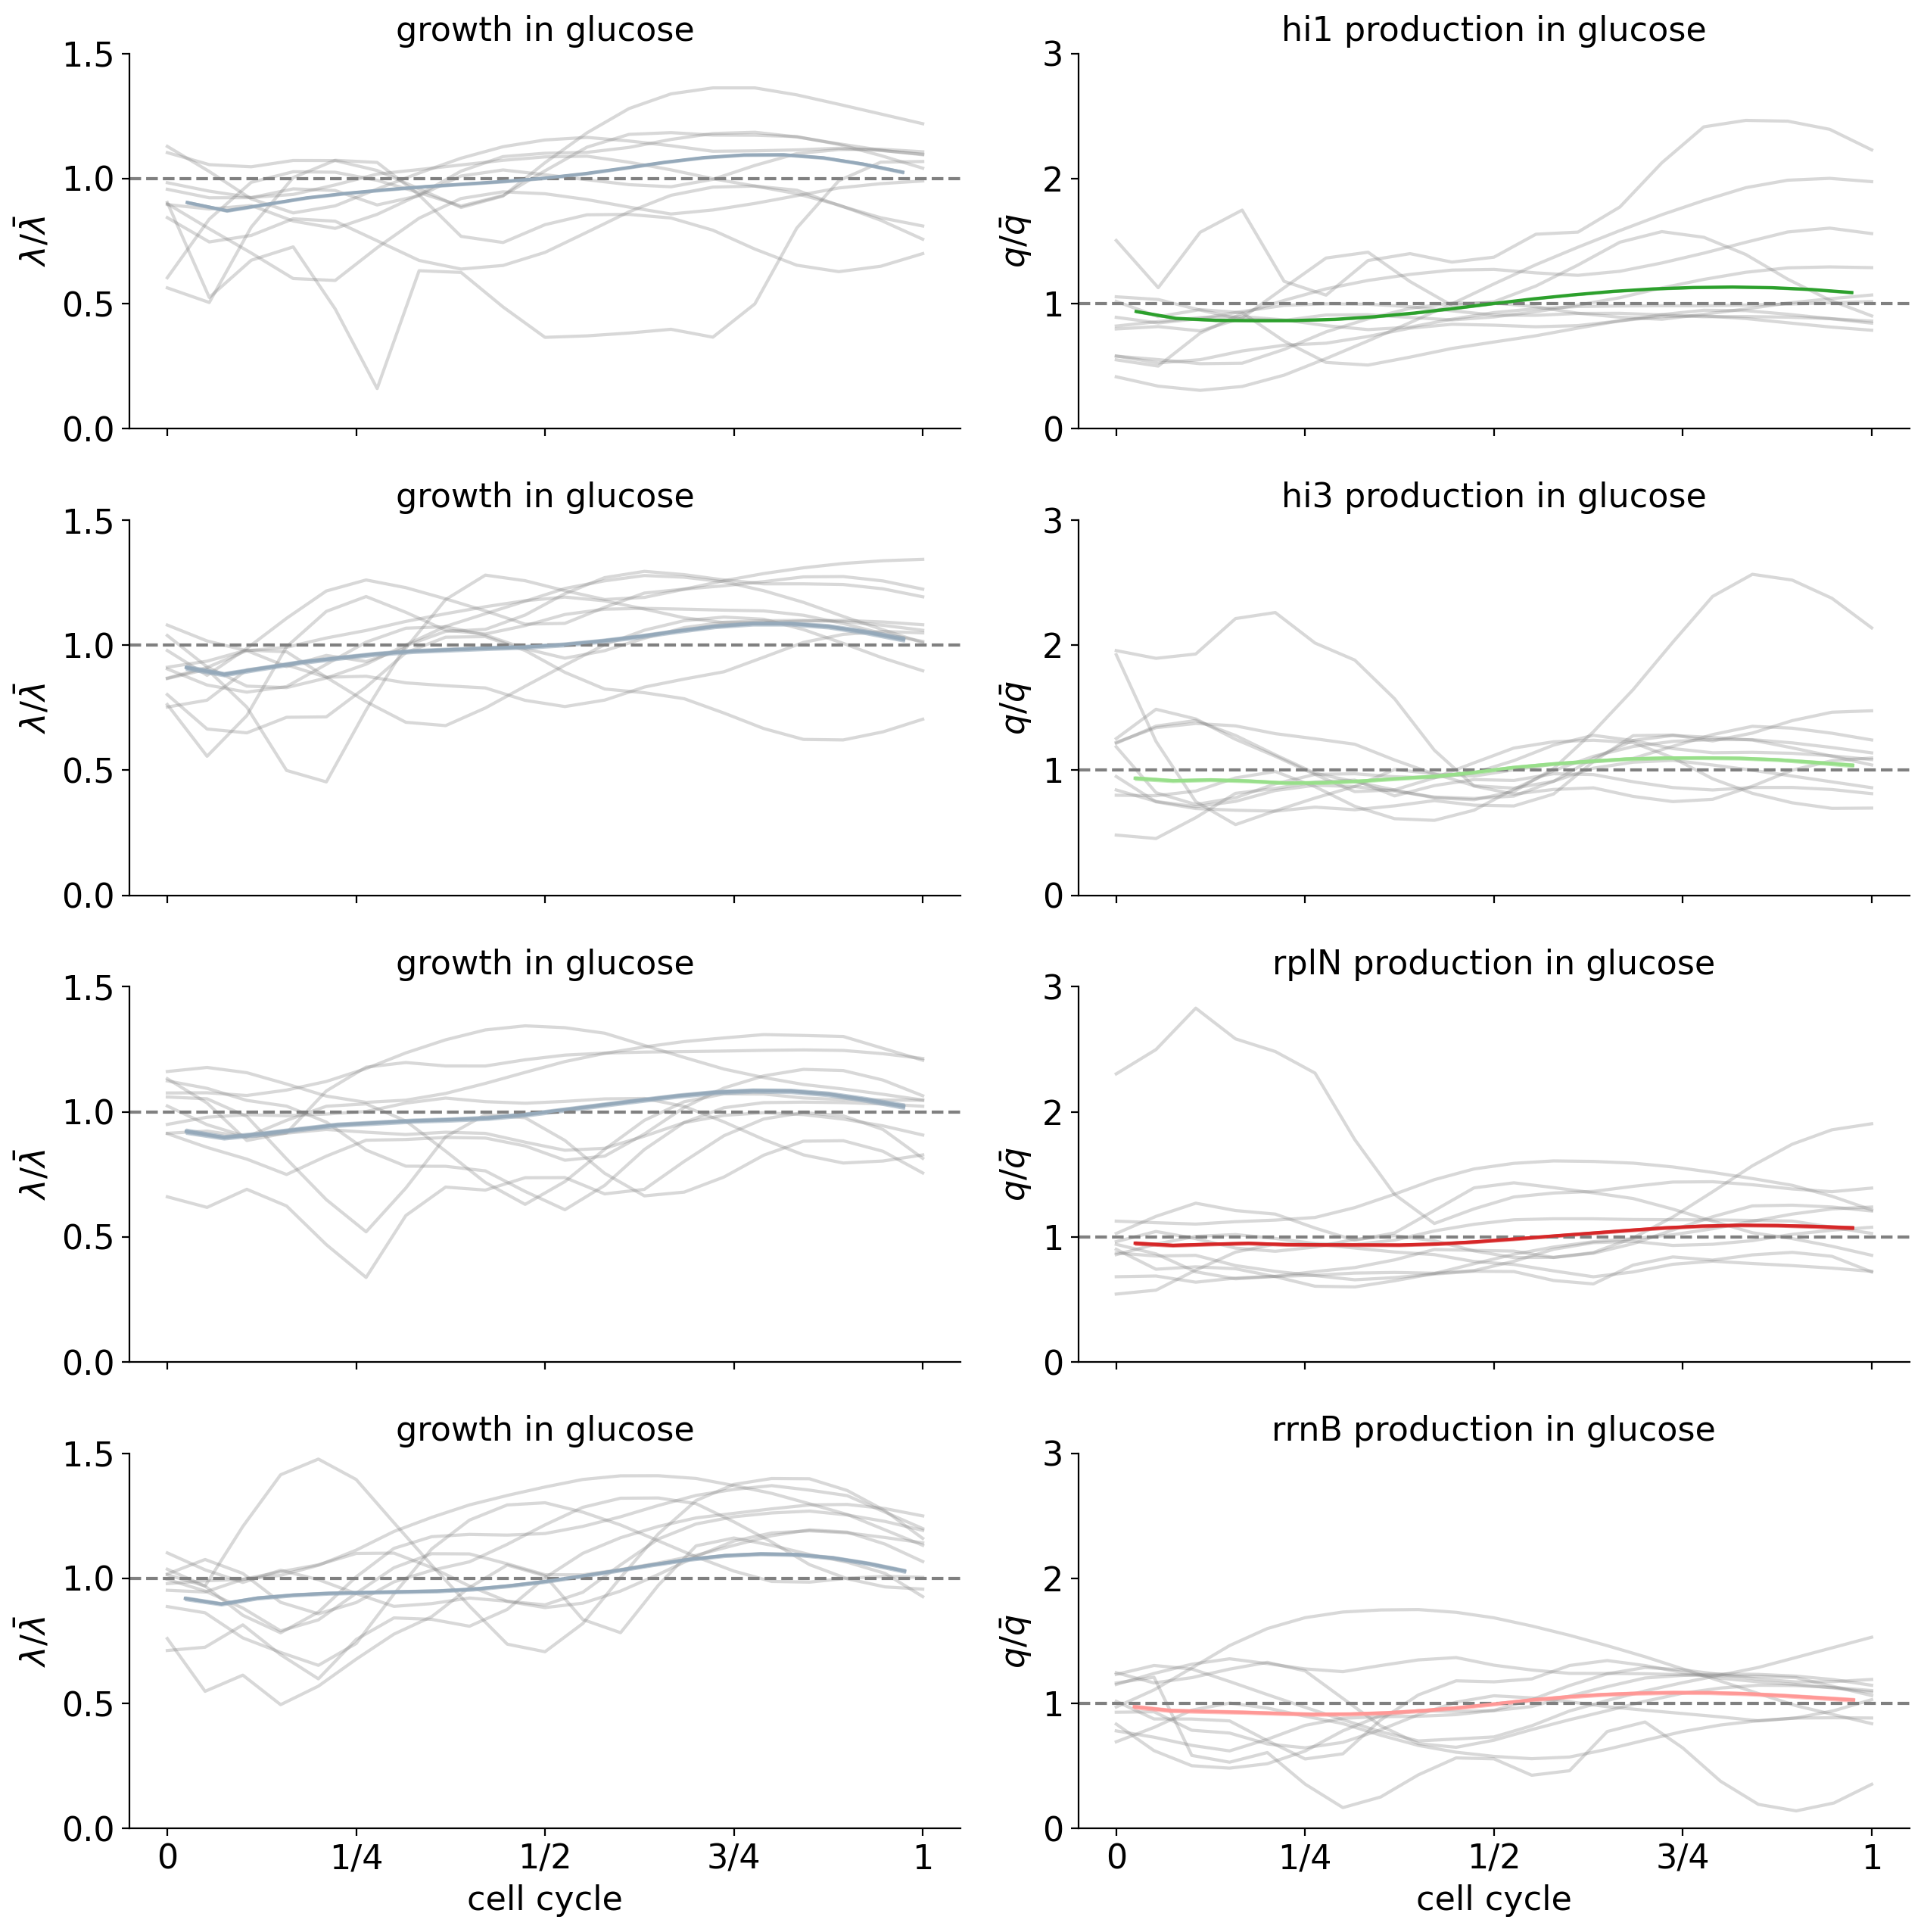

In [14]:
np.random.seed(1)
def added_volume_dependence_all_without_cdf_seperate(all_filenames,  
                                                    xlim=[None, None], 
                                                    ylim=[None, None],
                                                    hist_xlim=[None, None],
                                                    outfile=None, 
                                                    show=True, 
                                                    norm_q=False, 
                                                    norm_l=False,
                                                    plot_scatter=False,
                                                    plot_all=False,
                                                    xaxis_parameter="volume",
                                                    alignment="norm", 
                                                    growth_rate_unit=60,
                                                    label="both",
                                                    title=None,
                                                    interpolate=None,
                                                    color_code="condition", 
                                                    bins=10, 
                                                    show_cc_corr=False,
                                                    legend=True):
    
    """ needs a prediction file, start, stop, step refers to cells """

    fig, axes = plt.subplots(4,2, figsize=(FULL_SIZE, FULL_SIZE), sharex=True)
    for a in axes.ravel():
            a.spines["top"].set_visible(False)
            a.spines["right"].set_visible(False)
            a.spines['right'].set_color('none')
            a.yaxis.tick_left()
            a.spines['top'].set_color('none')
            a.xaxis.tick_bottom()
    

    for i, filename in enumerate(all_filenames):
        ax = axes[i,:]
        ax0, ax1 = ax[0], ax[1]

        data_set_name = re.split('_f\d', filename.split('/')[-1] )[0]
        condition = data_set_name.split("_")[0]
        promoter = data_set_name.split("_")[1]

        ax0.set_title( "growth in " + label_by_condition[condition] )
        ax1.set_title( promoter+ " production in " + label_by_condition[condition] )

        if i == 0:
            labeli = promoter
        else:
            labeli = None

        altcolor_by_promoter = {p: col for p,col  in zip(['hi1','hi3','rplN','rrnB'], ["#2ca02c" ,"#98df8a" ,"#d62728" ,"#ff9896"])}
        altcolor_by_condition = {cond: col for cond,col  in zip(conditions, ["#101518", "#5e798f", "#95a9ba", "#adbdc9" ])}

        condition_color = altcolor_by_condition[condition]
        promoter_color = altcolor_by_promoter[promoter]

        data = pd.read_csv(filename, skiprows=header_lines(filename))
        cells_data = df2ggp_cells(data)

        collect_mean_l = np.array([])
        collect_var_l = np.array([])

        collect_mean_q = np.array([])
        collect_var_q = np.array([])

        xaxis = np.array([])
        xaxis_cc = np.array([])
        if interpolate!=None:
            if interpolate=="auto":
                n_d = 0
                for cell in cells_data:
                    n_d += len(cell.time)
                n_interpolate=int(n_d/len(cells_data))
                bins=n_interpolate
            else:
                n_interpolate = interpolate
                bins=n_interpolate

        for _, cell in enumerate(cells_data):
            if len(cell.time)<2:
                continue

            if xaxis_parameter == "volume":
                single_cell_xaxis = np.exp(cell.mean_x)
            elif xaxis_parameter == "time":
                single_cell_xaxis = np.array(cell.time)

            if alignment=="norm":                    
                dx = (single_cell_xaxis -single_cell_xaxis[0])  \
                    / (single_cell_xaxis[-1] - single_cell_xaxis[0]) 

            elif alignment== "birth":
                dx = single_cell_xaxis - single_cell_xaxis[0]
            else:
                return

            if interpolate!=None:
                linspace = np.linspace(dx[0], dx[-1], n_interpolate)
                cell.mean_l=np.interp(linspace, dx, cell.mean_l)
                cell.cov_ll=np.interp(linspace, dx, cell.cov_ll)

                cell.mean_q=np.interp(linspace, dx, cell.mean_q)
                cell.cov_qq=np.interp(linspace, dx, cell.cov_qq)
                dx = linspace


            xaxis_cc = np.append(xaxis_cc, single_cell_xaxis[-1] - single_cell_xaxis[0])
            xaxis = np.append(xaxis, dx)

            collect_mean_l = np.append(collect_mean_l, cell.mean_l)
            collect_var_l = np.append(collect_var_l, cell.cov_ll)

            collect_mean_q = np.append(collect_mean_q, cell.mean_q)
            collect_var_q = np.append(collect_var_q, cell.cov_qq)

        mean_l, bin_edges,_ = stats.binned_statistic(xaxis, collect_mean_l,statistic='mean', bins=bins)
        sum_l, _,_   = stats.binned_statistic(xaxis, collect_var_l, statistic='sum', bins=bins)
        count_l, _,_   = stats.binned_statistic(xaxis, collect_var_l, statistic='count', bins=bins)
        std_l = np.sqrt(sum_l / count_l**2)

        if norm_l:
            ax0.axhline(1, color="grey", ls='--')
            normalization_l = np.mean(collect_mean_l)
            mean_l = mean_l/normalization_l
            std_l = std_l/normalization_l
            collect_mean_l/=normalization_l

        ## q
        mean_q, bin_edges,_ = stats.binned_statistic(xaxis, collect_mean_q,statistic='mean', bins=bins)
        sum_q, _,_   = stats.binned_statistic(xaxis, collect_var_q, statistic='sum', bins=bins)
        count_q, _,_   = stats.binned_statistic(xaxis, collect_var_q, statistic='count', bins=bins)

        std_q = np.sqrt(sum_q / count_q**2)
        if norm_q:
            ax1.axhline(1, color="grey", ls='--')
            normalization_q = np.mean(collect_mean_q)
            mean_q = mean_q/normalization_q
            std_q = std_q/normalization_q
            collect_mean_q = collect_mean_q/normalization_q

        ax0.plot(bin_edges[:-1]+np.diff(bin_edges)/2, mean_l, color=condition_color)
        ax0.fill_between(bin_edges[:-1]+np.diff(bin_edges)/2,
                         mean_l+std_l, 
                         mean_l-std_l, 
                         alpha=0.6, color=condition_color)


        ax1.plot(bin_edges[:-1]+np.diff(bin_edges)/2, 
                 mean_q, 
                 color=promoter_color, label=labeli)
        ax1.fill_between(bin_edges[:-1]+np.diff(bin_edges)/2, mean_q+std_q, mean_q-std_q, alpha=0.6, 
                         color=promoter_color)

        if plot_all:
            for _, cell in enumerate(np.random.choice(cells_data, 10)):
                if len(cell.time)<2:
                    continue

                if xaxis_parameter == "volume":
                    single_cell_xaxis = np.exp(cell.mean_x)
                elif xaxis_parameter == "time":
                    single_cell_xaxis = np.array(cell.time)

                if alignment=="norm":                    
                    dx = (single_cell_xaxis -single_cell_xaxis[0])  \
                        / (single_cell_xaxis[-1] - single_cell_xaxis[0]) 

                elif alignment== "birth":
                    dx = single_cell_xaxis - single_cell_xaxis[0]
                else:
                    return

                if interpolate!=None:
                    linspace = np.linspace(dx[0], dx[-1], n_interpolate)
                    dx = linspace
                ax0.plot(dx, cell.mean_l/normalization_l, color="tab:grey", zorder=-10, alpha=0.3)
                ax1.plot(dx, cell.mean_q/normalization_q, color="tab:grey", zorder=-10, alpha=0.3)
                if condition.startswith("acet"):
                    ax0.set_ylim(0,2.5)
                    ax1.set_ylim(-1,4)
                if condition.startswith("glyc"):
                    ax0.set_ylim(0,2)
                    ax1.set_ylim(-1,4)
                if condition.startswith("gluc"):
                    ax0.set_ylim(0,1.5)
                    ax1.set_ylim(0,3)

        ax0.set_ylabel(r"$\lambda/\bar{\lambda}$")   
        ax1.set_ylabel(r"$q/\bar{q}$")   

        if i==3:
            for a in [ax0, ax1]:
                a.set_xlabel("cell cycle")  
                a.set_xticks(np.arange(0, 1.25, 0.25))
                a.set_xticklabels(["0", "1/4", "1/2", "3/4", "1"])

    fig.tight_layout()

    if outfile != None:
        fig.savefig(outfile.format(xaxis_parameter, alignment), dpi=200, facecolor="white", bbox_inches="tight")
        print("Saved:", outfile)
        plt.show()
        
        plt.close('all')
    elif show:
        plt.show()
    else:
        return ax
# ==================================================== #

promoters_to_plot = ['hi1', 'hi3', 'rplN', 'rrnB']

for i in range(3):
    files_for_plot = [file for file in prediction_files \
                      if  file.split("/")[-1].split("_")[0] in [conditions[i]] \
                      and file.split("/")[-1].split("_")[1] in promoters_to_plot]    
        # =========== cc =========== #

    added_volume_dependence_all_without_cdf_seperate(files_for_plot,  
        outfile=os.path.join("../../figures_for_method_paper/supp/supp_cell_cycle/{:s}_cc.pdf".format(label_by_condition[conditions[i]]) ), 
        norm_l=True, 
        norm_q=True, 
        plot_all=True,
        xaxis_parameter="volume",
        alignment="norm", 
        interpolate="auto",
        color_code="promoter",
        label="promoter", 
        legend=True,
        title = label_by_condition[condition] )


# added length distr.

/Library/Frameworks/Python.framework/Versions/3.7/lib/python3.7/site-packages/numpy/core/fromnumeric.py:87: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


Saved: ../../figures_for_method_paper/supp/supp_cell_cycle/added_length_distr.pdf


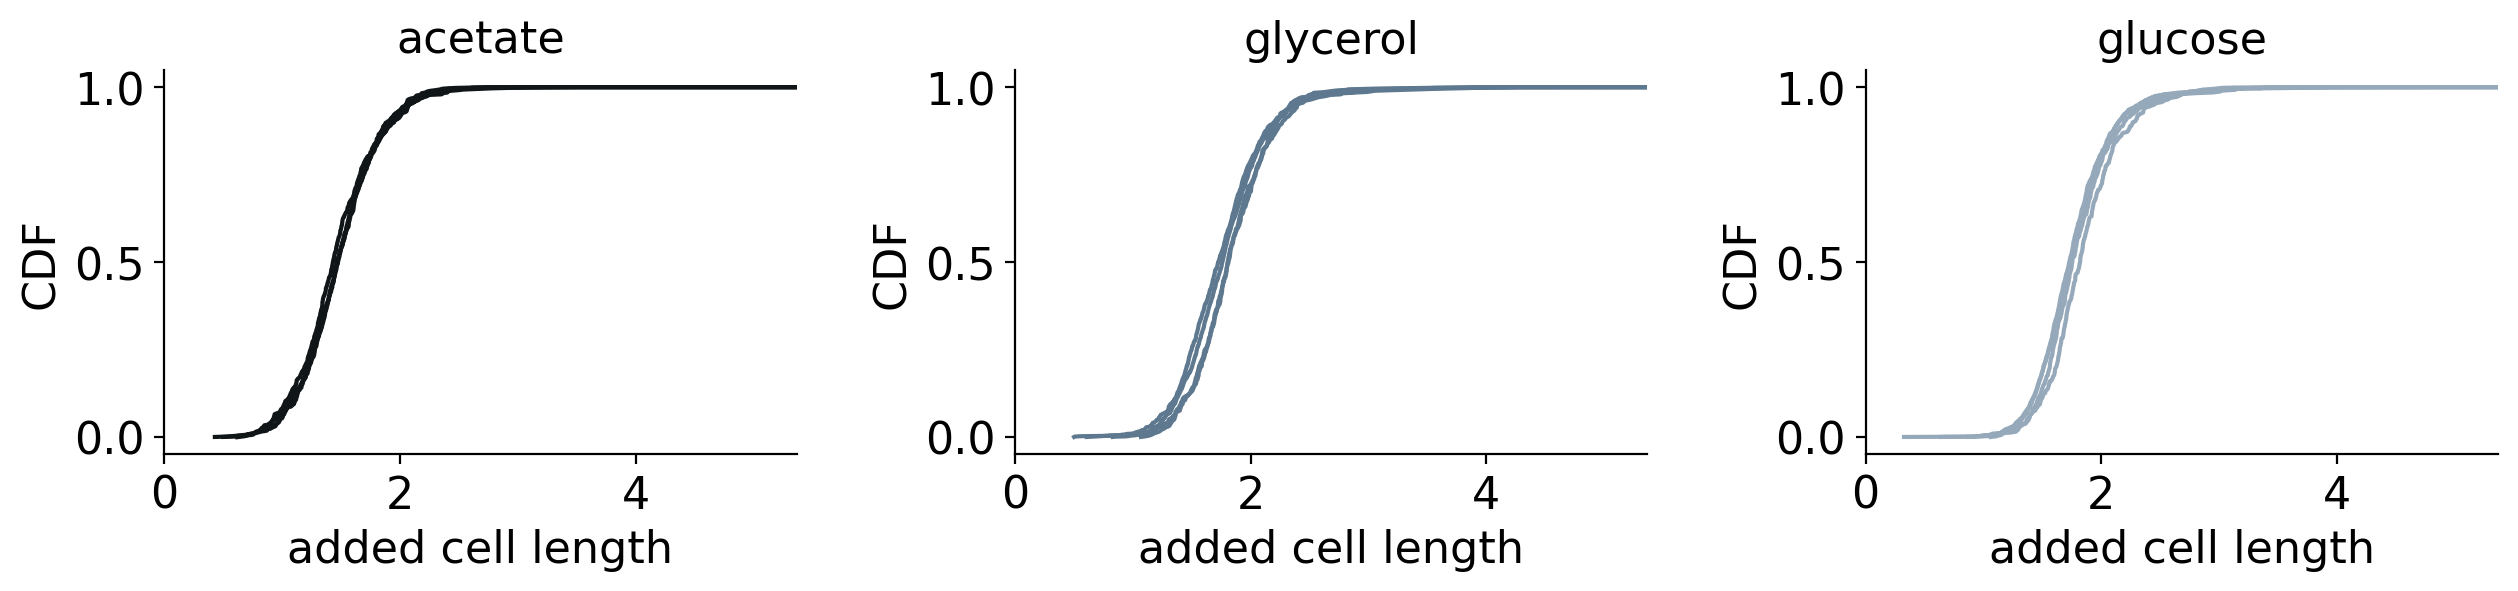

In [15]:
def added_volume_distr(filenames,  
                        hist_xlim=[None, None],
                        outfile=None, 
                        show=True, 
                        title=None,
                        color_code="condition", 
                       legend=True):
    
    """ needs a prediction file, start, stop, step refers to cells """

    fig, ax = plt.subplots(1, 3, figsize=(FULL_SIZE, FULL_HEIGHT*0.8))
    ax = ax.ravel()
        
    for a in ax:
        a.set_title(title)
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)
        a.spines['right'].set_color('none')
        a.yaxis.tick_left()
        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()

    longest_cc = []
    
    for j, condition_in_plot in enumerate(conditions[:3]):
        ax[j].set_title(label_by_condition[condition_in_plot])
        for filename in filenames:
            data_set_name = re.split('_f\d', filename.split('/')[-1] )[0]
            condition = data_set_name.split("_")[0]
            if condition !=condition_in_plot:
                continue
            promoter = data_set_name.split("_")[1]

            altcolor_by_promoter = {p: col for p,col  in zip(['hi1','hi3','rplN','rrnB'], ["#2ca02c" ,"#98df8a" ,"#d62728" ,"#ff9896"])}
            altcolor_by_condition = {cond: col for cond,col  in zip(conditions, ["#101518", "#5e798f", "#95a9ba", "#adbdc9" ])}

            condition_color = altcolor_by_condition[condition]
            promoter_color = altcolor_by_promoter[promoter]

            data = pd.read_csv(filename, skiprows=header_lines(filename))
            cells_data = df2ggp_cells(data)
            xaxis_cc = [np.exp(cell.mean_x[-1]) - np.exp(cell.mean_x[0]) for cell in cells_data]
                

            ax[j].plot(np.append(np.sort(xaxis_cc), 10), np.append(np.linspace(0.0,1.0,len(xaxis_cc)), 1), 
                      color=condition_color)
            
            longest_cc =  np.max([longest_cc, np.max(xaxis_cc)])
        

    for a in ax:
        a.set_xlim([0, longest_cc])

        a.set_xlabel("added cell length")  
        a.set_ylabel("CDF")  

    fig.tight_layout()

    if outfile != None:
        fig.savefig(outfile, dpi=600, facecolor="white", bbox_inches="tight")
        print("Saved:", outfile)
        plt.show()
        
        plt.close('all')
    elif show:
        plt.show()
    else:
        return ax
# ==================================================== #

promoters_to_plot = ['hi1', 'hi3', 'rplN', 'rrnB']

files_for_plot = [file for file in prediction_files \
                  if  file.split("/")[-1].split("_")[0] in [conditions[0],conditions[1], conditions[2]] \
                  and file.split("/")[-1].split("_")[1] in promoters_to_plot]    

added_volume_distr(files_for_plot,  
                    hist_xlim=[None, None],
                    outfile=os.path.join("../../figures_for_method_paper/supp/supp_cell_cycle/added_length_distr.pdf" ), 
                    show=True, 
                    title=None,
                    color_code="condition", 
                   legend=True)

/Library/Frameworks/Python.framework/Versions/3.7/lib/python3.7/site-packages/numpy/core/fromnumeric.py:87: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


Saved: ../../figures_for_method_paper/supp/supp_cell_cycle/added_length_distr.pdf


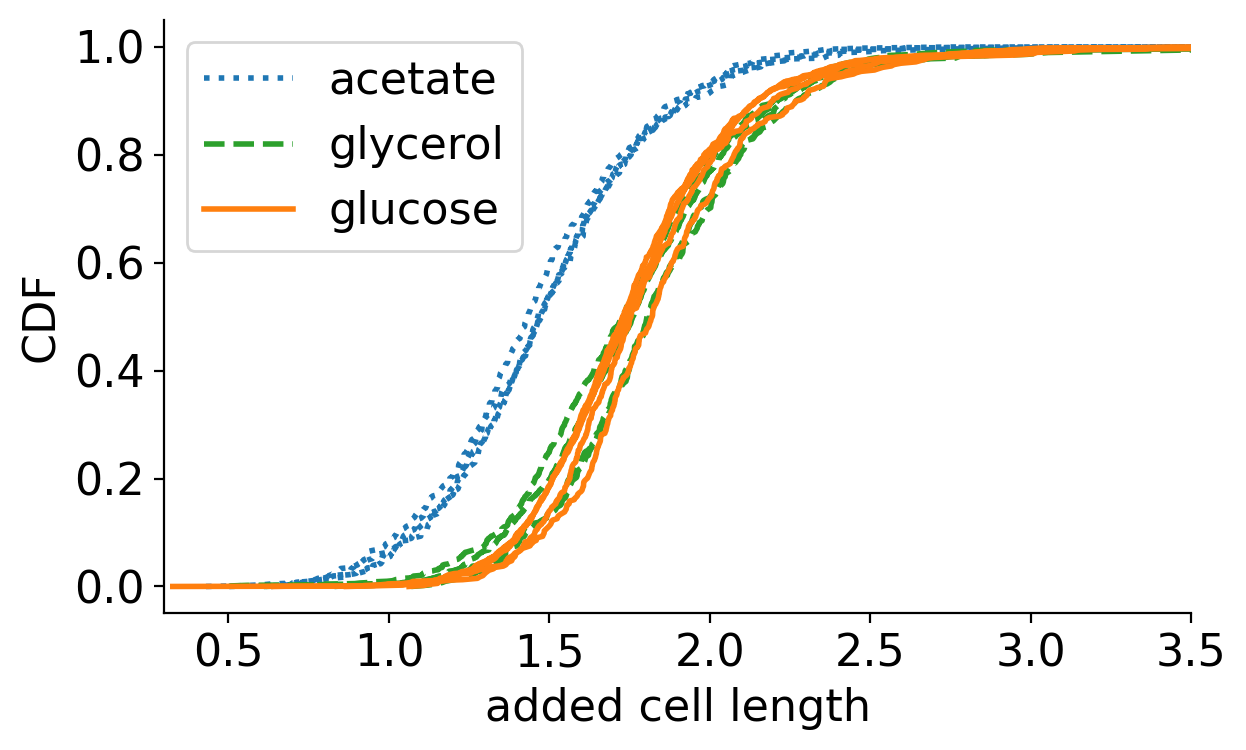

In [16]:
def added_volume_distr_single_panel(filenames,  
                                    hist_xlim=[None, None],
                                    outfile=None, 
                                    show=True, 
                                    title=None,
                                    color_code="condition", 
                                   legend=True):

    """ needs a prediction file, start, stop, step refers to cells """

    fig, ax = plt.subplots(1, 1, figsize=(FULL_SIZE/2, FULL_HEIGHT))
        
    for a in [ax]:
        a.set_title(title)
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)
        a.spines['right'].set_color('none')
        a.yaxis.tick_left()
        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()

    longest_cc = []
    
    ls = [":", "--", "-"]
    for j, condition_in_plot in enumerate(conditions[:3]):
        label=label_by_condition[condition_in_plot]
        
        for i, filename in enumerate(filenames):
            data_set_name = re.split('_f\d', filename.split('/')[-1] )[0]
            condition = data_set_name.split("_")[0]
            if condition !=condition_in_plot:
                continue
            promoter = data_set_name.split("_")[1]

            altcolor_by_promoter = {p: col for p,col  in zip(['hi1','hi3','rplN','rrnB'], ["#2ca02c" ,"#98df8a" ,"#d62728" ,"#ff9896"])}
            # altcolor_by_condition = {cond: col for cond,col  in zip(conditions, ["#101518", "#2f3c47", "#95a9ba", "#adbdc9" ])}
            altcolor_by_condition = {cond: col for cond,col  in zip(conditions, ["tab:blue", "tab:green", "tab:orange", "#adbdc9" ])}

            condition_color = altcolor_by_condition[condition]
            promoter_color = altcolor_by_promoter[promoter]

            data = pd.read_csv(filename, skiprows=header_lines(filename))
            cells_data = df2ggp_cells(data)
            xaxis_cc = [np.exp(cell.mean_x[-1]) - np.exp(cell.mean_x[0]) for cell in cells_data]
                

            ax.plot(np.append(np.sort(xaxis_cc), 10), 
                    np.append(np.linspace(0.0,1.0,len(xaxis_cc)), 1), 
                      color=condition_color, 
                    ls=ls[j], 
                    label=label,
                   lw=2, 
                   )
            label=None
            
            longest_cc =  np.max([longest_cc, np.max(xaxis_cc)])
        
    ax.legend()
    for a in [ax]:
        a.set_xlim([0.3, 3.5])

        a.set_xlabel("added cell length")  
        a.set_ylabel("CDF")  

    fig.tight_layout()

    if outfile != None:
        fig.savefig(outfile, dpi=600, facecolor="white", bbox_inches="tight")
        print("Saved:", outfile)
        plt.show()
        
        plt.close('all')
    elif show:
        plt.show()
    else:
        return ax
# ==================================================== #

promoters_to_plot = ['hi1', 'hi3', 'rplN', 'rrnB']

files_for_plot = [file for file in prediction_files \
                  if  file.split("/")[-1].split("_")[0] in [conditions[0],conditions[1], conditions[2]] \
                  and file.split("/")[-1].split("_")[1] in promoters_to_plot]    

added_volume_distr_single_panel(files_for_plot,  
                                hist_xlim=[None, None],
                                outfile=os.path.join("../../figures_for_method_paper/supp/supp_cell_cycle/added_length_distr.pdf" ), 
                                show=True, 
                                title=None,
                                color_code="condition", 
                               legend=True)

acetate005 8.902916666666666
acetate005 9.101709401709401
acetate005 7.653163152053273
acetate005 8.015151515151514
glycerol040 5.772705078125
glycerol040 5.552791262135922
glycerol040 5.3506825938566545
glycerol040 5.7636509635974305
glucose020 4.741138059701492
glucose020 4.9308206106870225
glucose020 4.884085213032581
glucose020 5.144411262798634


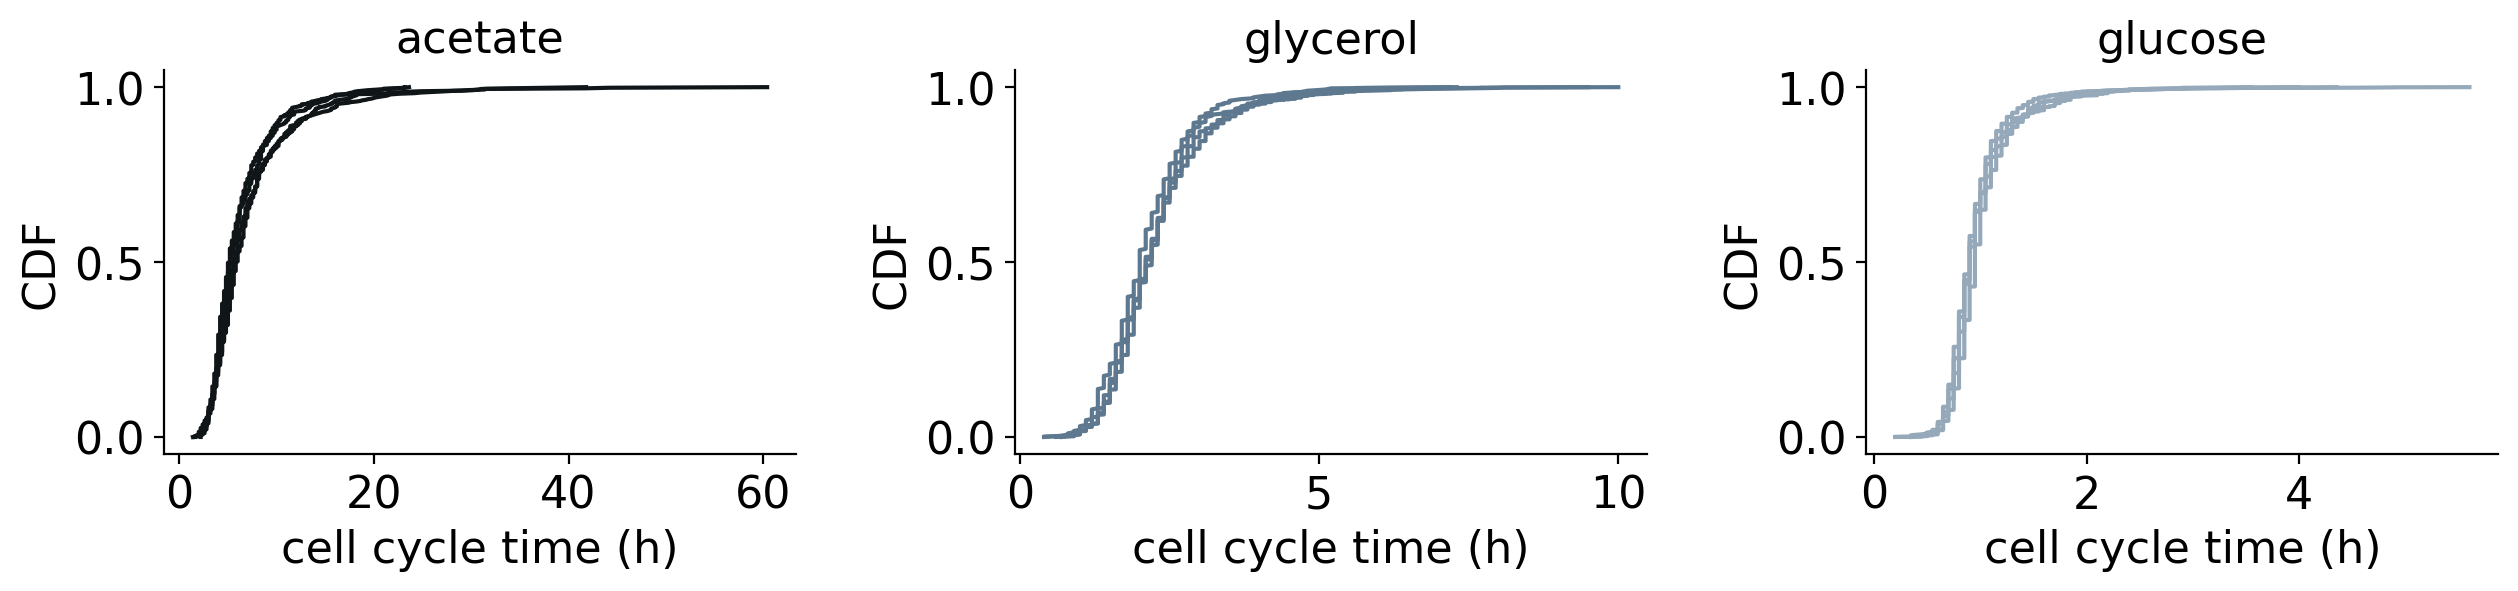

In [17]:
def cc_time_distr(filenames,  
                        hist_xlim=[None, None],
                        outfile=None, 
                        show=True, 
                        title=None,
                        color_code="condition", 
                       legend=True):
    
    """ needs a prediction file, start, stop, step refers to cells """

    fig, ax = plt.subplots(1, 3, figsize=(FULL_SIZE, FULL_HEIGHT*0.8))
    ax = ax.ravel()
        
    for a in ax:
        a.set_title(title)
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)
        a.spines['right'].set_color('none')
        a.yaxis.tick_left()
        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()

    longest_cc = []
    altcolor_by_promoter = {p: col for p,col  in zip(['hi1','hi3','rplN','rrnB'], ["#2ca02c" ,"#98df8a" ,"#d62728" ,"#ff9896"])}
    altcolor_by_condition = {cond: col for cond,col  in zip(conditions, ["#101518", "#5e798f", "#95a9ba", "#adbdc9" ])}

    
    aqui = {cond: t for cond,t  in zip(conditions, [12, 6 , 3 ,1.5 ])}
    for j, condition_in_plot in enumerate(conditions[:3]):
        ax[j].set_title(label_by_condition[condition_in_plot])
        for filename in filenames:
            data_set_name = re.split('_f\d', filename.split('/')[-1] )[0]
            condition = data_set_name.split("_")[0]
            if condition !=condition_in_plot:
                continue
            promoter = data_set_name.split("_")[1]


            condition_color = altcolor_by_condition[condition]

            data = pd.read_csv(filename, skiprows=header_lines(filename))
            cells_data = df2ggp_cells(data)
            xaxis_cc = [ (cell.time[-1]-cell.time[0])/60. for cell in cells_data]
                
        
            ax[j].plot(np.sort(xaxis_cc), np.linspace(0.0,1.0,len(xaxis_cc)), 
                      color=condition_color)
            
            print(condition,np.mean(xaxis_cc)*0.25/(aqui[condition]/60.))

    for a in ax:
        a.set_xlabel("cell cycle time (h)")  
        a.set_ylabel("CDF")  

    fig.tight_layout()

    if outfile != None:
        fig.savefig(outfile, dpi=600, facecolor="white", bbox_inches="tight")
        print("Saved:", outfile)
        plt.show()
        
        plt.close('all')
    elif show:
        plt.show()
    else:
        return ax
# ==================================================== #

promoters_to_plot = ['hi1', 'hi3', 'rplN', 'rrnB']

files_for_plot = [file for file in prediction_files \
                  if  file.split("/")[-1].split("_")[0] in [conditions[0],conditions[1], conditions[2]] \
                  and file.split("/")[-1].split("_")[1] in promoters_to_plot]    

cc_time_distr(files_for_plot,  
                hist_xlim=[None, None],
                show=True, 
                title=None,
                color_code="condition", 
               legend=True)